# Learning Activity 4: Modeling and Commercial Strategy (Actividad 4: Modelado y Estrategia Comercial)
**Business Case:** North Quay Gifts | **Dataset:** Online Retail II (`online_retail_II.csv`)  
**CRISP-DM Phases:** Phase 4 — Modeling & Phase 5 — Evaluation (with Commercial Strategy)  

**Team Members:**
- Russel Emmanuel Ku Aguilar (ID: 2309131)
- Damian Nicolas Sanchez Novelo (ID: 2109134)
- Jonathan Abisai Velasco Martín (ID: 2309060)
- Ángel Rivaldo Canché Chuc (ID: 2309030)
- Bianca Alexandra Acosta Castellanos (ID: 2309001)

**Academic Advisor / Professor:** Didier Omar Gamboa Angulo (`didier.gamboa@upy.edu.mx`)  
**Institution:** Faculty of Data Engineering, Universidad Politécnica de Yucatán (UPY)

---
### Methodological Governance & Forensic Continuity
This notebook closes the CRISP-DM cycle for North Quay Gifts by connecting the forensic discoveries from **A-3-3 (Data Understanding)**, **A-3-4 (Data Cleaning & Processing)**, and **A-3-5 (Data Construction)** into high-performance predictive models and an evidence-based commercial decision matrix.

1. **Section I – Daily Revenue Forecasting:** One-step-ahead regression over 60 test trading days (expanding-window time series CV, Linear Regression vs. Random Forest vs. Naive).
2. **Section II – 90-Day Repurchase Classification:** Supervised modeling under strict zero-leakage cut (`< 2011-07-01`), comparing the 3-feature baseline against the 9-feature forensic-enriched set (Logistic Regression, Decision Trees, Random Forest, Gradient Boosting), plus deconstruction of the **462 seasonal late repurchasers** in Q4.
3. **Section III – Customer Segmentation (RFM):** K-Means clustering ($K=4$) with preprocessing audit (`log1p` + `StandardScaler` / `RobustScaler`), sensitivity analysis between Classic RFM vs. Forensic RFM (`Frequency_NetHotFix`, `Monetary_Merchandise`), recovery of M-code accounts (e.g., 14063, 17017), and enrichment with marketing proxies (`DISCOUNT_UserFlag`, `CohortYear`, `IsUK`, `TrueReturnRate`).
4. **Section IV & V – Commercial Strategy & Alignment:** Prioritized customer ranking, cancellation-risk governance, and multidimensional decision matrix for B2B wholesale, Q4 holiday reactivation, and new cohort onboarding.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score, brier_score_loss, silhouette_score)
from sklearn.cluster import KMeans
import sklearn

warnings.filterwarnings('ignore')

SEED = 42
ROUTE = 'B'
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'axes.edgecolor': '#333333', 'axes.linewidth': 0.8, 'font.size': 10, 'font.sans-serif': ['DejaVu Sans', 'Arial']})
pd.set_option('display.width', 200); pd.set_option('display.max_columns', None)
os.makedirs('figures', exist_ok=True); os.makedirs('outputs', exist_ok=True)
gbp = mticker.FuncFormatter(lambda x, p: f'£{x:,.0f}')
R = {'seed': SEED, 'route': ROUTE}
print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| seed', SEED, '| route', ROUTE)

pandas 3.0.2 | scikit-learn 1.8.0 | seed 42 | route B


---
# Section I – Sales regression and forecast (Regresión y pronóstico de ventas)
**Question:** what sales can we expect, and how can that forecast support commercial planning?

### I.1 Design
- **Target:** daily `Revenue` (GBP, Route B net of credits). `TotalOrders` is used only for operational context, never as a predictor.
- **Time unit:** one **observed trading day**. The store has no records on most Sundays, on some Saturdays and during the
  Christmas closure; those dates are **not** filled with zeros because there is no evidence of zero sales (Activity 2).
- **Forecast type:** **one step ahead** — each forecast is issued at the close of an observed day for the **next observed
  trading day**. At issue time we know all revenue up to and including the issue day; once the next day is observed it is added
  to the history before forecasting the following one. No orders or units of the target day are used.
- **Test block:** the last **60 observed trading days** (2011-10-02 to 2011-12-09), kept untouched until the final evaluation.
- **Lags are in rows, not days:** `lag1` is the previous *observed* day, which can be 1–4 calendar days earlier (e.g., Friday →
  Monday). The feature `GapDays` (calendar days since the previous observed day) and day-of-week dummies make that explicit.

In [2]:
daily = pd.read_csv('../A-3-4_DataCleaning/outputs/indicadores_diarios.csv', parse_dates=['Date']).set_index('Date').sort_index()
print('Rows:', len(daily), '| first:', daily.index.min().date(), '| last:', daily.index.max().date())
print('Calendar days in range:', (daily.index.max() - daily.index.min()).days + 1, '→ observed days are', len(daily))
gaps = daily.index.to_series().diff().dt.days.value_counts().sort_index()
print('Gap between consecutive observed days (calendar days → count):', gaps.to_dict())
print('Observed days by weekday (0=Mon):', daily.index.dayofweek.value_counts().sort_index().to_dict())
display(daily.describe().round(2))

,TotalOrders,TotalUnits,Revenue
count,604.00,604.00,604.00
mean,66.35,17762.13,31479.86
std,24.78,11650.88,16514.55
min,11.00,-63859.00,-1727.65
25%,49.00,11411.50,20944.03
50%,63.00,15667.50,27846.39
75%,80.00,21512.25,39105.89
max,153.00,122733.00,111958.62


Rows: 604 | first: 2009-12-01 | last: 2011-12-09
Calendar days in range: 739 → observed days are 604
Gap between consecutive observed days (calendar days → count): {1.0: 495, 2.0: 103, 3.0: 1, 5.0: 2, 12.0: 2}
Observed days by weekday (0=Mon): {0: 94, 1: 104, 2: 104, 3: 103, 4: 99, 5: 1, 6: 99}


In [3]:
s = daily['Revenue']
feat = pd.DataFrame(index=s.index)
feat['y'] = s
for k in (1, 2, 3, 5, 6):
    feat[f'Lag{k}'] = s.shift(k)                      # previous observed days (rows)
feat['RollMean5'] = s.shift(1).rolling(5).mean()      # mean of the 5 previous observed days
feat['RollMean20'] = s.shift(1).rolling(20).mean()    # ≈ previous 4 trading weeks
feat['RollMedian5'] = s.shift(1).rolling(5).median()
feat['GapDays'] = feat.index.to_series().diff().dt.days
feat['DayOfWeek'] = feat.index.dayofweek
feat['Month'] = feat.index.month
feat['DayOfYear'] = feat.index.dayofyear
feat['Trend'] = np.arange(len(feat))
feat = feat.dropna()                                   # first 20 observed days lack a full window
dow = pd.get_dummies(feat['DayOfWeek'].astype(pd.CategoricalDtype(range(7))), prefix='DOW').astype(float)
feat = pd.concat([feat, dow], axis=1)

TEST_N = 60
train, test = feat.iloc[:-TEST_N], feat.iloc[-TEST_N:]
print('Modelling rows:', len(feat), '| train:', train.index.min().date(), '→', train.index.max().date(), f'({len(train)})',
      '| test:', test.index.min().date(), '→', test.index.max().date(), f'({len(test)})')
DOW_COLS = list(dow.columns)
F_INITIAL = ['Lag1', 'Lag2', 'Lag5', 'RollMean5', 'RollMean20'] + DOW_COLS
F_ALT = F_INITIAL + ['Lag3', 'Lag6', 'RollMedian5', 'GapDays', 'Month', 'DayOfYear', 'Trend']
R['fc_design'] = dict(rows=len(daily), model_rows=len(feat),
                       train=[str(train.index.min().date()), str(train.index.max().date()), len(train)],
                       test=[str(test.index.min().date()), str(test.index.max().date()), len(test)])

Modelling rows: 584 | train: 2009-12-23 → 2011-09-30 (524) | test: 2011-10-02 → 2011-12-09 (60)


### I.2 Candidates and selection inside the training block
| Role | Model | Features |
|---|---|---|
| Reference | **Naive**: next observed day = last observed value (`Lag1`) | — |
| Initial model | **Linear regression** (standardized inside a pipeline) | 2 lags, 3 recent means, day of week |
| Alternative | **Random forest** (300 trees) with a bounded search of `min_samples_leaf` ∈ {5, 10, 20} | initial features + more lags, gap, month, day of year, trend |

Selection uses **expanding-window time-series cross-validation inside the training block** (`TimeSeriesSplit`, 5 folds of 40
observed days). **Metric:** Mean Absolute Error (MAE), matching the company's financial criterion.

In [4]:
def make_model(kind, leaf=None):
    if kind == 'Linear regression':
        return make_pipeline(StandardScaler(), LinearRegression())
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1)

candidates = [('Naive (last value)', None, None, None), ('Linear regression', 'Linear regression', None, F_INITIAL)]
candidates += [(f'Random forest (leaf={l})', 'Random forest', l, F_ALT) for l in (5, 10, 20)]
tscv = TimeSeriesSplit(n_splits=5, test_size=40)
rows = []
for name, kind, leaf, cols in candidates:
    maes = []
    for a, b in tscv.split(train):
        tr, va = train.iloc[a], train.iloc[b]
        if kind is None:
            pred = va['Lag1']
        else:
            m = make_model(kind, leaf).fit(tr[cols], tr['y'])
            pred = m.predict(va[cols])
        maes.append(mean_absolute_error(va['y'], pred))
    rows.append(dict(Model=name, Mean_MAE=np.mean(maes), Std_MAE=np.std(maes)))
cv_res = pd.DataFrame(rows).set_index('Model').sort_values('Mean_MAE')
display(cv_res.round(2))
selected = cv_res.index[0]
best_rf = [m for m in cv_res.index if 'Random forest' in m][0]
print(f'Selected model by CV inside training: {selected} (MAE {cv_res.loc[selected, "Mean_MAE"]:.2f})')
print(f'Best Random forest: {best_rf} (MAE {cv_res.loc[best_rf, "Mean_MAE"]:.2f})')
R['fc_cv'] = {k: float(v) for k, v in cv_res['Mean_MAE'].items()}
R['fc_selected'] = selected; R['fc_best_rf'] = best_rf

,Mean_MAE,Std_MAE
Model,,
Linear regression,7936.67,2227.32
Random forest (leaf=5),8144.31,2093.17
Random forest (leaf=10),8244.03,1937.20
Random forest (leaf=20),8333.12,1840.96
Naive (last value),13011.88,2761.59


Selected model by CV inside training: Linear regression (MAE 7936.67)
Best Random forest: Random forest (leaf=5) (MAE 8144.31)


### I.3 Final evaluation on the test block (same 60 dates for every model)
Each model is refit once on the full training block. In the test block each forecast uses only revenue observed up to the
issue day (one step ahead).

In [5]:
leaf_rf = int(best_rf.split('=')[1].rstrip(')'))
fitted = {
    'Naive (last value)': None,
    'Linear regression': make_model('Linear regression').fit(train[F_INITIAL], train['y']),
    'Random forest (leaf=5)': make_model('Random forest', leaf_rf).fit(train[F_ALT], train['y'])
}
pred = pd.DataFrame(index=test.index)
pred['Actual'] = test['y']
pred['Naive (last value)'] = test['Lag1']
pred['Linear regression'] = fitted['Linear regression'].predict(test[F_INITIAL])
pred['Random forest (leaf=5)'] = fitted['Random forest (leaf=5)'].predict(test[F_ALT])

metrics = []
for m in ['Naive (last value)', 'Linear regression', 'Random forest (leaf=5)']:
    y_true, y_pred = pred['Actual'], pred[m]
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    metrics.append(dict(Model=m, MAE=mae, RMSE=rmse, R2=r2))
ev = pd.DataFrame(metrics).set_index('Model')
naive_mae, naive_rmse = ev.loc['Naive (last value)', 'MAE'], ev.loc['Naive (last value)', 'RMSE']
ev['MAE vs naive %'] = 100 * (ev['MAE'] - naive_mae) / naive_mae
ev['RMSE vs naive %'] = 100 * (ev['RMSE'] - naive_rmse) / naive_rmse
display(ev.round(2))

tr_pred = fitted['Linear regression'].predict(train[F_INITIAL])
tr_mae = mean_absolute_error(train['y'], tr_pred)
tr_rmse = np.sqrt(mean_squared_error(train['y'], tr_pred))
tr_r2 = r2_score(train['y'], tr_pred)
print(f'Linear regression on TRAIN: MAE £{tr_mae:,.2f} | RMSE £{tr_rmse:,.2f} | R2 {tr_r2:.3f}')
print(f'Linear regression on TEST:  MAE £{ev.loc["Linear regression", "MAE"]:,.2f} | RMSE £{ev.loc["Linear regression", "RMSE"]:,.2f} | R2 {ev.loc["Linear regression", "R2"]:.3f}')
R['fc_test'] = {k: {m: float(v) for m, v in r.items()} for k, r in ev.iterrows()}
R['fc_train_selected'] = dict(MAE=float(tr_mae), RMSE=float(tr_rmse), R2=float(tr_r2))
R['fc_test_stats'] = dict(mean_rev=float(test['y'].mean()), total=float(test['y'].sum()),
                           mean_orders=float(daily.loc[test.index, 'TotalOrders'].mean()),
                           rev_per_order=float(test['y'].sum() / daily.loc[test.index, 'TotalOrders'].sum()))

,MAE,RMSE,R2,MAE vs naive %,RMSE vs naive %
Model,,,,,
Naive (last value),18359.95,23954.15,-0.73,0.00,0.00
Linear regression,11451.27,15580.40,0.27,-37.63,-34.96
Random forest (leaf=5),10155.44,14002.18,0.41,-44.69,-41.55


Linear regression on TRAIN: MAE £8,147.15 | RMSE £11,436.58 | R2 0.406
Linear regression on TEST:  MAE £11,451.27 | RMSE £15,580.40 | R2 0.269


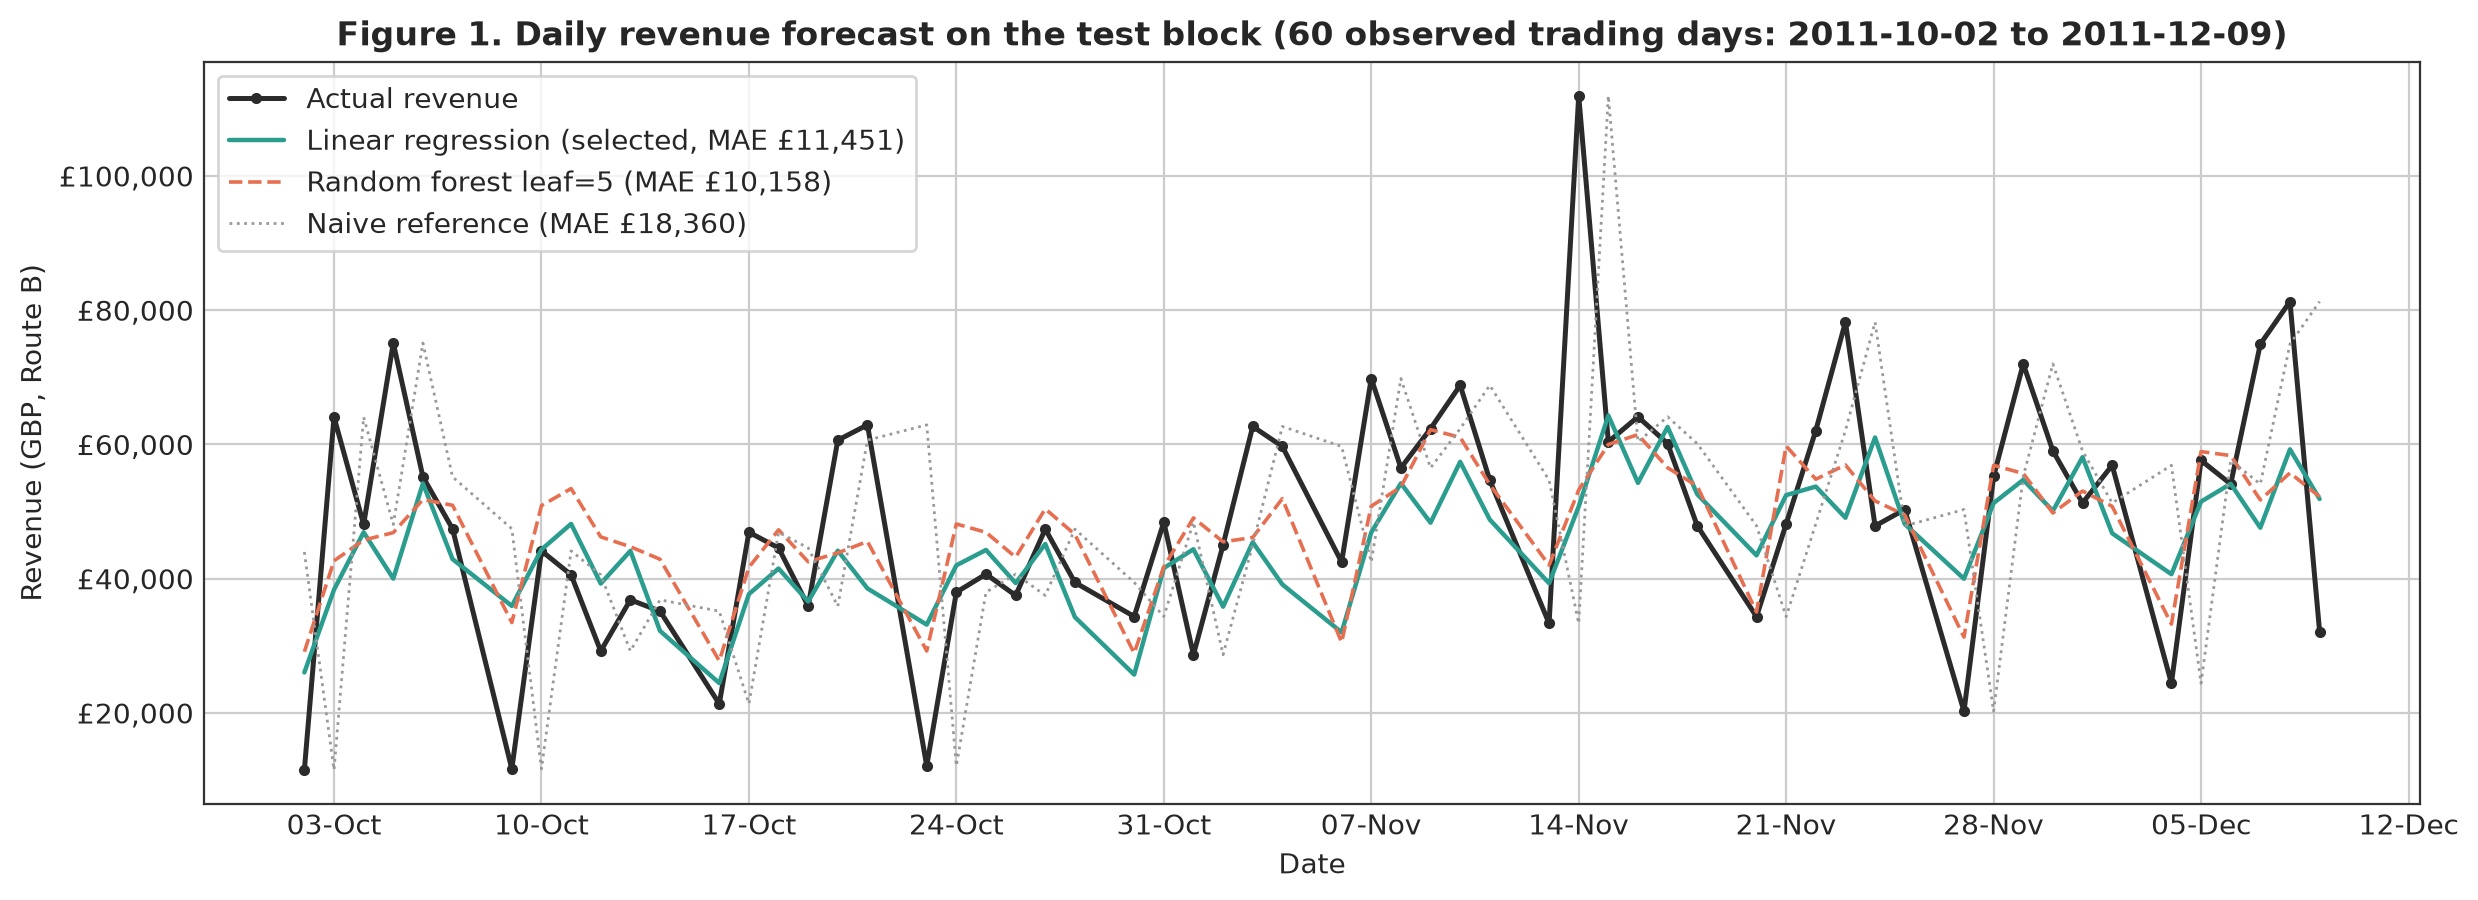

Figure 1 saved to figures/fig1_forecast_test.png


In [6]:
fig, ax = plt.subplots(figsize=(12.5, 4.6), dpi=200)
ax.plot(pred.index, pred['Actual'], label='Actual revenue', color='#2b2b2b', lw=1.8, marker='o', ms=3)
ax.plot(pred.index, pred['Linear regression'], label='Linear regression (selected, MAE £11,451)', color='#2a9d8f', lw=1.6)
ax.plot(pred.index, pred['Random forest (leaf=5)'], label='Random forest leaf=5 (MAE £10,158)', color='#e76f51', lw=1.3, ls='--')
ax.plot(pred.index, pred['Naive (last value)'], label='Naive reference (MAE £18,360)', color='#999999', lw=1.0, ls=':')
ax.set_title('Figure 1. Daily revenue forecast on the test block (60 observed trading days: 2011-10-02 to 2011-12-09)', fontweight='bold')
ax.set_xlabel('Date'); ax.set_ylabel('Revenue (GBP, Route B)')
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('£{x:,.0f}'))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
ax.legend(frameon=True, facecolor='white', loc='upper left')
fig.tight_layout(); fig.savefig('figures/fig1_forecast_test.png', bbox_inches='tight'); plt.show()
print('Figure 1 saved to figures/fig1_forecast_test.png')

### I.4 The two largest errors of the selected model and their planning meaning

In [7]:
err = pred[['Actual', selected, 'Naive (last value)']].copy()
err['Error'] = err[selected] - err['Actual']                 # positive = over-forecast
err['AbsError'] = err['Error'].abs()
err['Orders'] = daily.loc[err.index, 'TotalOrders']
top2 = err.sort_values('AbsError', ascending=False).head(2)
display(top2.round(2))
rpo = R['fc_test_stats']['rev_per_order']
top2_out = []
for d_, r in top2.iterrows():
    kind = 'over-forecast' if r.Error > 0 else 'under-forecast'
    print(f"{d_.date()} ({d_.day_name()}): {kind} of £{abs(r.Error):,.0f} = {100*abs(r.Error)/R['fc_test_stats']['mean_rev']:.0f}% of an average test day "
          f"≈ {abs(r.Error)/rpo:.0f} orders at the test-period average of £{rpo:,.0f} per order")
    top2_out.append(dict(date=str(d_.date()), dow=d_.day_name(), actual=float(r.Actual), forecast=float(r[selected]), error=float(r.Error), orders=int(r.Orders)))
R['fc_top2'] = top2_out
display(daily.loc[top2.index])
bias = err['Error'].mean()
print(f"Mean error (bias) of the selected model on test: £{bias:,.0f} per day ({'over' if bias > 0 else 'under'}-forecast on average); "
      f"share of days under-forecast: {100 * (err['Error'] < 0).mean():.0f}%")
R['fc_bias'] = dict(mean=float(bias), under_share=float((err['Error'] < 0).mean()))

,Actual,Linear regression,Naive (last value),Error,AbsError,Orders
Date,,,,,,
2011-11-14,111958.62,50759.18,33341.65,-61199.44,61199.44,107
2011-10-05,75111.57,40019.93,48082.73,-35091.64,35091.64,96


,TotalOrders,TotalUnits,Revenue
Date,,,
2011-11-14,107,47043,111958.62
2011-10-05,96,46045,75111.57


2011-11-14 (Monday): under-forecast of £61,199 = 124% of an average test day ≈ 116 orders at the test-period average of £526 per order
2011-10-05 (Wednesday): under-forecast of £35,092 = 71% of an average test day ≈ 67 orders at the test-period average of £526 per order
Mean error (bias) of the selected model on test: £-4,111 per day (under-forecast on average); share of days under-forecast: 58%


In [8]:
wk = pred.groupby(pred.index.to_period('W-SUN')).agg(Days=('Actual', 'size'), Actual=('Actual', 'sum'), Forecast=(selected, 'sum'), Naive=('Naive (last value)', 'sum'))
wk['Error %'] = 100 * (wk['Forecast'] - wk['Actual']) / wk['Actual']
wk['Naive error %'] = 100 * (wk['Naive'] - wk['Actual']) / wk['Actual']
display(wk.round(1))
print('Note: the first and last weeks are partial (test starts on a Sunday and ends on Friday Dec 9).')
R['fc_weekly_mape'] = dict(model=float(wk['Error %'].abs().mean()), naive=float(wk['Naive error %'].abs().mean()))
R['fc_total'] = dict(actual=float(pred['Actual'].sum()), model=float(pred[selected].sum()), naive=float(pred['Naive (last value)'].sum()))
full = wk[wk.Days >= 6]
peak = full.loc[[p for p in full.index if pd.Timestamp('2011-10-31') <= p.start_time <= pd.Timestamp('2011-11-14')]]
R['fc_weeks'] = dict(total_gap_pct=float(100 * (pred[selected].sum() - pred['Actual'].sum()) / pred['Actual'].sum()),
                     full_weeks_mean_gap_pct=float(full['Error %'].mean()), peak_min=float(peak['Error %'].max()), peak_max=float(peak['Error %'].min()),
                     weeks=[dict(week=str(p.start_time.date()), days=int(r.Days), actual=float(r.Actual), forecast=float(r.Forecast), gap=float(r['Error %'])) for p, r in wk.iterrows()])
print(f"Whole test block: forecast {100 * (pred[selected].sum() / pred['Actual'].sum() - 1):.1f}% vs actual; mean gap of full weeks {full['Error %'].mean():.1f}%; "
      f"peak weeks Oct 31 – Nov 20: {peak['Error %'].max():.1f}% to {peak['Error %'].min():.1f}%")

pred.round(2).to_csv('outputs/forecast_test_predictions.csv')
print('Saved outputs/forecast_test_predictions.csv')

,Days,Actual,Forecast,Naive,Error %,Naive error %
Date,,,,,,
2011-09-26/2011-10-02,1,11520.6,26039.3,43982.8,126.0,281.8
2011-10-03/2011-10-09,6,301565.4,258376.6,301415.1,-14.3,-0.0
2011-10-10/2011-10-16,6,207345.6,232632.3,197654.1,12.2,-4.7
2011-10-17/2011-10-23,6,263103.8,231735.8,272346.4,-11.9,3.5
2011-10-24/2011-10-30,6,237399.1,230821.0,215146.9,-2.8,-9.4
2011-10-31/2011-11-06,6,287017.9,238414.7,278910.3,-16.9,-2.8
2011-11-07/2011-11-13,6,345524.7,295012.0,354662.7,-14.6,2.6
2011-11-14/2011-11-20,6,378849.8,328040.2,377838.8,-13.4,-0.3
2011-11-21/2011-11-27,6,306886.9,304468.8,320999.8,-0.8,4.6


Note: the first and last weeks are partial (test starts on a Sunday and ends on Friday Dec 9).
Whole test block: forecast -8.3% vs actual; mean gap of full weeks -7.6%; peak weeks Oct 31 – Nov 20: -13.4% to -16.9%
Saved outputs/forecast_test_predictions.csv


---
# Section II – Classification and repurchase strategies (Clasificación y estrategias de recompra)
**Question:** which profiles are more or less likely to repurchase, and which commercial actions should be tested?

Input: `clientes_clasificacion.csv` (July 2011 snapshot). Predictors: `RecencyDays`, `TotalOrders`, `TotalSpent` (180 days before
2011-07-01, Route B). Target: `Repurchase90Days` (1 = at least one valid purchase in the next 90 days). `CustomerID` is an
identifier only. **Positive class = 1.**

In [9]:
cls = pd.read_csv('../A-3-5_DataConstruction/outputs/clientes_clasificacion.csv')
FEATS = ['RecencyDays', 'TotalOrders', 'TotalSpent']
X, y = cls[FEATS], cls['Repurchase90Days']
bal = y.value_counts().sort_index().to_frame('Customers'); bal['%'] = (100 * bal['Customers'] / len(y)).round(2)
display(bal)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
split = pd.DataFrame({'Train': y_tr.value_counts().sort_index(), 'Test': y_te.value_counts().sort_index()})
split.loc['% class 1'] = [100 * y_tr.mean(), 100 * y_te.mean()]
display(split.round(2))
R['cl_balance'] = {str(k): int(v) for k, v in y.value_counts().sort_index().items()}
R['cl_split'] = dict(train=len(y_tr), test=len(y_te), train_pos=float(y_tr.mean()), test_pos=float(y_te.mean()))

,Customers,%
Repurchase90Days,,
0,1315,48.27
1,1409,51.73


,Train,Test
Repurchase90Days,,
0,1052.00,263.00
1,1127.00,282.00
% class 1,51.72,51.74


### II.1 Main metric & Initial Decision Trees (Historical Rubric)
The two actions (a loyalty offer for likely repurchasers and a reactivation contact for unlikely ones) both need the model to
separate the classes in a balanced way: missing repurchasers wastes the loyalty audience and contacting non-repurchasers wastes
budget. With almost balanced classes, the **main selection metric is F1 of class 1**; Precision and Recall of both classes are
reported to size each audience.

### II.2 Initial tree and bounded search
- **Initial tree:** `DecisionTreeClassifier(random_state=42)` with default (unbounded) depth.
- **Search:** `max_depth` ∈ {3, 4, 5} × `min_samples_leaf` ∈ {20, 50, 100}, 5-fold **stratified** CV inside training
  (`shuffle=True, random_state=42`), scoring = F1 (class 1). The best combination is refit on all training data (`refit=True`).

In [10]:
tree0 = DecisionTreeClassifier(random_state=SEED).fit(X_tr, y_tr)
grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
                    {'max_depth': [3, 4, 5], 'min_samples_leaf': [20, 50, 100]},
                    scoring='f1', cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), refit=True).fit(X_tr, y_tr)
res = pd.DataFrame(grid.cv_results_)[['param_max_depth', 'param_min_samples_leaf', 'mean_test_score', 'std_test_score', 'rank_test_score']]
display(res.sort_values('rank_test_score').round(4))
tree1 = grid.best_estimator_
print('Selected parameters:', grid.best_params_, '| mean CV F1:', round(grid.best_score_, 4))
print('Initial tree depth:', tree0.get_depth(), '| leaves:', tree0.get_n_leaves(), '|| selected tree depth:', tree1.get_depth(), '| leaves:', tree1.get_n_leaves())
R['cl_grid'] = dict(best=grid.best_params_, cv_f1=float(grid.best_score_), init_depth=int(tree0.get_depth()), init_leaves=int(tree0.get_n_leaves()),
                    sel_depth=int(tree1.get_depth()), sel_leaves=int(tree1.get_n_leaves()))

,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score,rank_test_score
4,4,50,0.6815,0.0092,1
0,3,20,0.6810,0.0290,2
5,4,100,0.6795,0.0173,3
2,3,100,0.6795,0.0297,4
3,4,20,0.6794,0.0090,5
1,3,50,0.6772,0.0252,6
8,5,100,0.6666,0.0285,7
6,5,20,0.6649,0.0205,8
7,5,50,0.6631,0.0183,9


Selected parameters: {'max_depth': 4, 'min_samples_leaf': 50} | mean CV F1: 0.6815
Initial tree depth: 30 | leaves: 726 || selected tree depth: 4 | leaves: 15


Accuracy  Precision  Recall     F1  Precision0  Recall0
Initial tree  Train     1.000      1.000   1.000  1.000       1.000    1.000
              Test      0.618      0.624   0.660  0.641       0.611    0.574
Selected tree Train     0.702      0.724   0.686  0.704       0.681    0.720
              Test      0.716      0.759   0.660  0.706       0.680    0.776

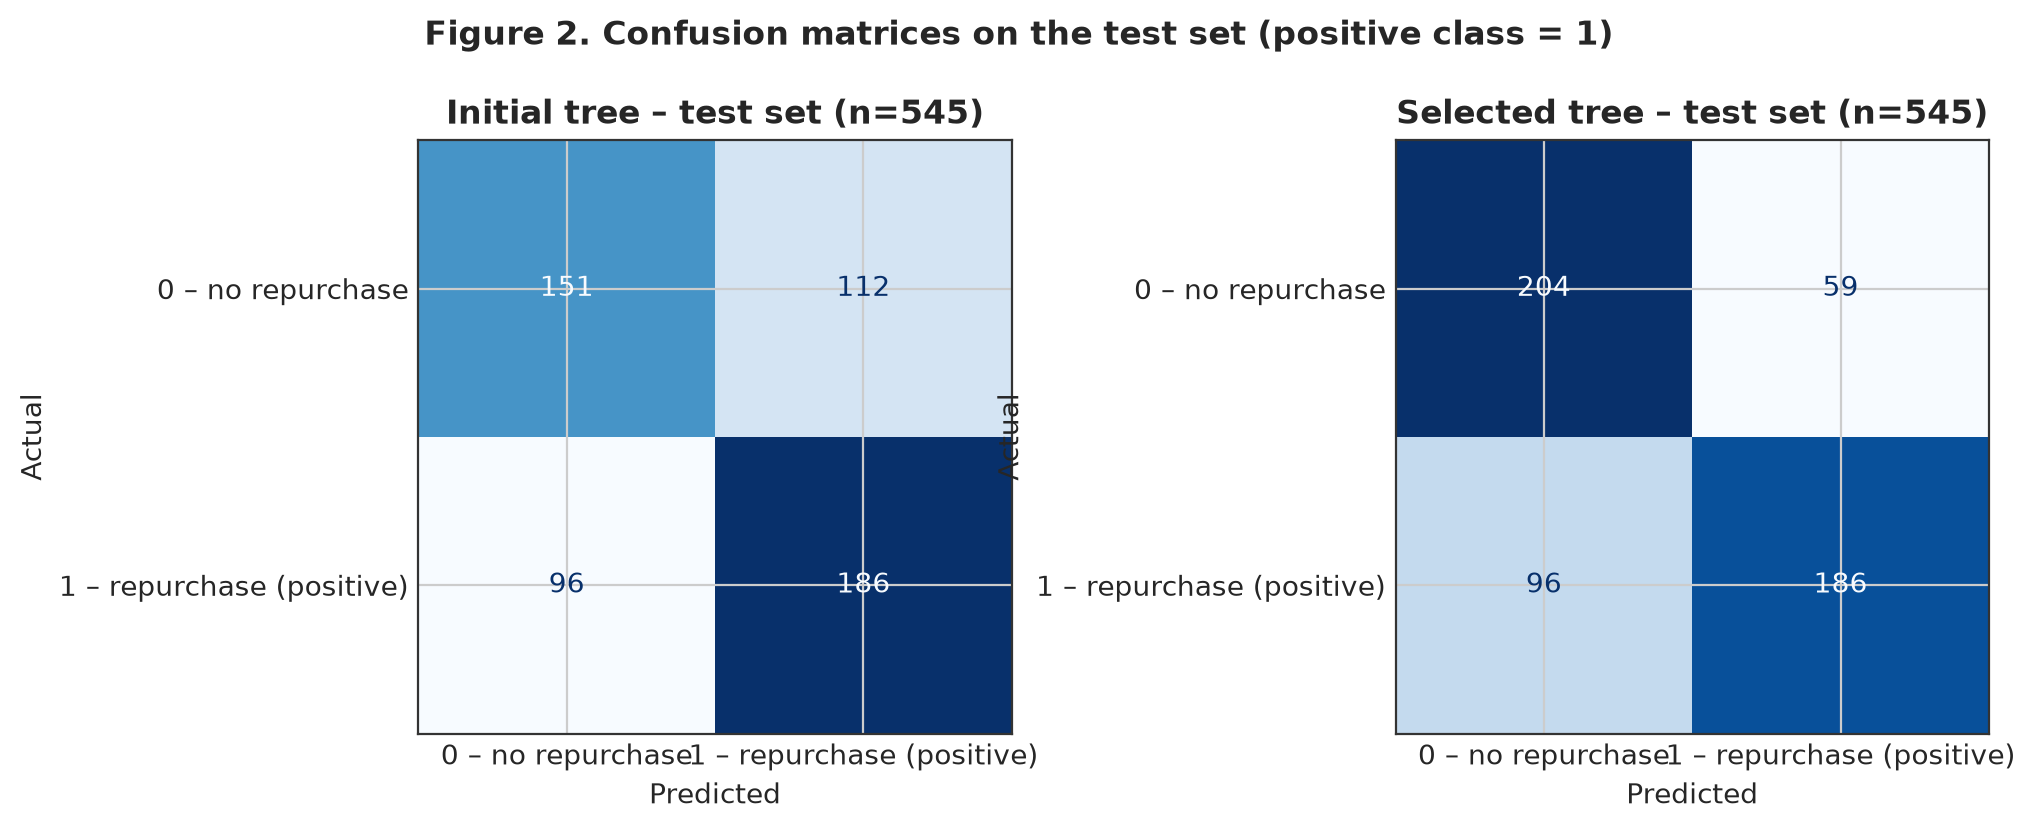

In [11]:
def scores(model, X_, y_):
    p = model.predict(X_)
    return dict(Accuracy=accuracy_score(y_, p), Precision=precision_score(y_, p), Recall=recall_score(y_, p), F1=f1_score(y_, p),
                Precision0=precision_score(y_, p, pos_label=0), Recall0=recall_score(y_, p, pos_label=0))
comp = pd.DataFrame({('Initial tree', 'Train'): scores(tree0, X_tr, y_tr), ('Initial tree', 'Test'): scores(tree0, X_te, y_te),
                     ('Selected tree', 'Train'): scores(tree1, X_tr, y_tr), ('Selected tree', 'Test'): scores(tree1, X_te, y_te)}).T
display(comp.round(3))
R['cl_metrics'] = {f'{a}|{b}': {k: float(v) for k, v in r.items()} for (a, b), r in comp.iterrows()}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), dpi=200)
cms = {}
for ax, (nm, m) in zip(axes, [('Initial tree', tree0), ('Selected tree', tree1)]):
    cm = confusion_matrix(y_te, m.predict(X_te), labels=[0, 1]); cms[nm] = cm.tolist()
    ConfusionMatrixDisplay(cm, display_labels=['0 – no repurchase', '1 – repurchase (positive)']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{nm} – test set (n={len(y_te)})', fontweight='bold'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
fig.suptitle('Figure 2. Confusion matrices on the test set (positive class = 1)', fontweight='bold')
fig.tight_layout(); fig.savefig('figures/fig2_confusion_matrices.png', bbox_inches='tight'); plt.show()
R['cl_cms'] = cms

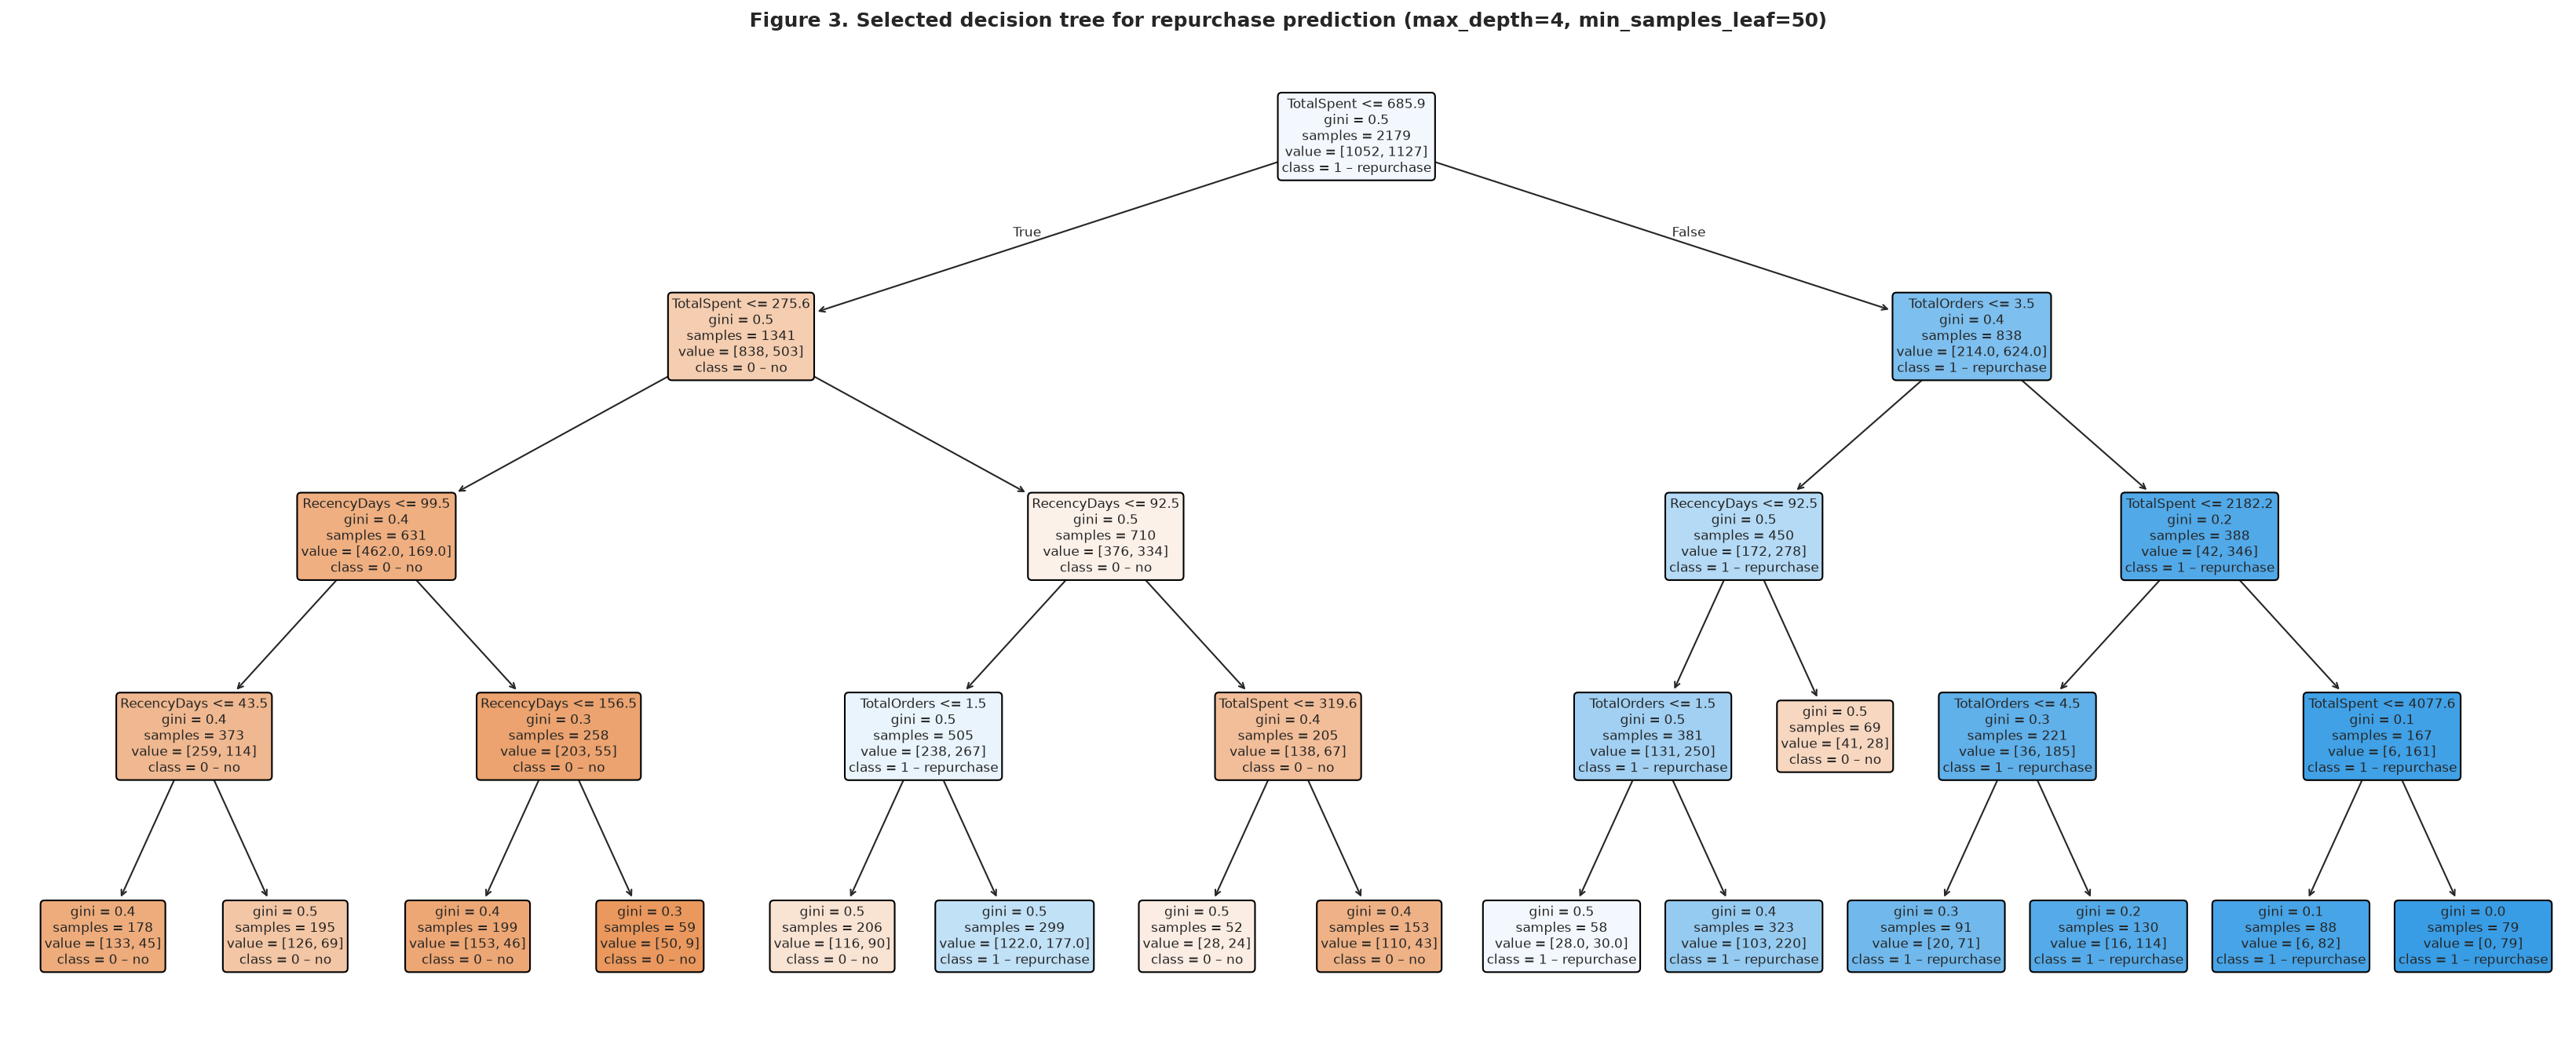

In [12]:
fig, ax = plt.subplots(figsize=(22, 9), dpi=150)
plot_tree(tree1, feature_names=FEATS, class_names=['0 – no', '1 – repurchase'], filled=True, rounded=True, precision=1, ax=ax, fontsize=8)
ax.set_title('Figure 3. Selected decision tree for repurchase prediction (max_depth=4, min_samples_leaf=50)', fontweight='bold', fontsize=12)
fig.tight_layout(); fig.savefig('figures/fig3_selected_tree.png', bbox_inches='tight'); plt.show()

In [13]:
t = tree1.tree_
leaf_tr = tree1.apply(X_tr)
leaf_te = tree1.apply(X_te)
rules = []
for leaf in np.unique(leaf_tr):
    n_tr = int((leaf_tr == leaf).sum())
    p_tr = float(y_tr[leaf_tr == leaf].mean())
    n_te = int((leaf_te == leaf).sum())
    p_te = float(y_te[leaf_te == leaf].mean()) if n_te > 0 else np.nan
    rules.append(dict(Leaf=int(leaf), Predicted=int(p_tr >= 0.5), TrainCustomers=n_tr, TrainRepurchase=p_tr, TestCustomers=n_te, TestRepurchase=p_te))
rules = pd.DataFrame(rules).sort_values('TrainRepurchase', ascending=False)
display(rules.round({'TrainRepurchase': 3, 'TestRepurchase': 3}))

rule_loyal = rules.iloc[0]
rule_react = rules.iloc[-1]
print('Selected single rules for commercial actions:')
for role, r in [('Loyalty rule (highest repurchase rate)', rule_loyal), ('Reactivation rule (lowest repurchase rate)', rule_react)]:
    print(f"- {role}: Leaf {r.Leaf} → predict {r.Predicted}\n  train: {r.TrainCustomers} customers, {100*r.TrainRepurchase:.1f}% repurchased | test: {r.TestCustomers} customers, {100*r.TestRepurchase:.1f}% repurchased")
    sub = X_tr[leaf_tr == r.Leaf]
    print('  training medians – RecencyDays %.0f, TotalOrders %.0f, TotalSpent £%.0f' % (sub.RecencyDays.median(), sub.TotalOrders.median(), sub.TotalSpent.median()))
R['cl_rules'] = rules.to_dict('records')
R['cl_rule_loyal'] = rule_loyal.to_dict(); R['cl_rule_react'] = rule_react.to_dict()
R['cl_base_rate'] = float(y_tr.mean())

,Leaf,Predicted,TrainCustomers,TrainRepurchase,TestCustomers,TestRepurchase
14,28,1,79,1.000,9,1.000
13,27,1,88,0.932,29,0.897
12,25,1,130,0.877,29,0.931
11,24,1,91,0.780,23,0.826
9,20,1,323,0.681,78,0.808
5,12,1,299,0.592,66,0.576
8,19,1,58,0.517,11,0.364
6,14,0,52,0.462,8,0.250
4,11,0,206,0.437,71,0.380
10,21,0,69,0.406,21,0.619


Selected single rules for commercial actions:
- Loyalty rule (highest repurchase rate): Leaf 28.0 → predict 1.0
  train: 79.0 customers, 100.0% repurchased | test: 9.0 customers, 100.0% repurchased
  training medians – RecencyDays 10, TotalOrders 12, TotalSpent £6594
- Reactivation rule (lowest repurchase rate): Leaf 8.0 → predict 0.0
  train: 59.0 customers, 15.3% repurchased | test: 11.0 customers, 9.1% repurchased
  training medians – RecencyDays 164, TotalOrders 1, TotalSpent £165


In [14]:
cm = np.array(cms['Selected tree']); tn, fp, fn, tp = cm.ravel()
aud = dict(test_n=int(len(y_te)), tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
           pred1=int(tp + fp), pred0=int(tn + fn), actual0=int(tn + fp), actual1=int(tp + fn),
           precision1=float(tp / (tp + fp)), recall1=float(tp / (tp + fn)), precision0=float(tn / (tn + fn)), recall0=float(tn / (tn + fp)))
print(f"Loyalty audience (predicted 1): {aud['pred1']} test customers; {aud['tp']} did repurchase (Precision 1 = {aud['precision1']:.3f}); "
      f"{aud['fp']} false positives = offers to customers who did not come back; {aud['fn']} false negatives = repurchasers left out of the loyalty list.")
print(f"Reactivation audience (predicted 0): {aud['pred0']} test customers; {aud['tn']} truly did not repurchase (Precision 0 = {aud['precision0']:.3f}); "
      f"{aud['fn']} repurchasers contacted unnecessarily; identifies {aud['tn']} of {aud['actual0']} non-repurchasers (Recall 0 = {aud['recall0']:.3f}); "
      f"{aud['fp']} non-repurchasers would remain unattended.")
full_pred = tree1.predict(X)
R['cl_audience'] = aud
R['cl_population_pred'] = dict(pred1=int((full_pred == 1).sum()), pred0=int((full_pred == 0).sum()),
                               loyal_rule=int((tree1.apply(X) == rule_loyal.Leaf).sum()), react_rule=int((tree1.apply(X) == rule_react.Leaf).sum()))
print('Whole July population (2,724):', R['cl_population_pred'])

Loyalty audience (predicted 1): 245 test customers; 186 did repurchase (Precision 1 = 0.759); 59 false positives = offers to customers who did not come back; 96 false negatives = repurchasers left out of the loyalty list.
Reactivation audience (predicted 0): 300 test customers; 204 truly did not repurchase (Precision 0 = 0.680); 96 repurchasers contacted unnecessarily; identifies 204 of 263 non-repurchasers (Recall 0 = 0.776); 59 non-repurchasers would remain unattended.
Whole July population (2,724): {'pred1': 1313, 'pred0': 1411, 'loyal_rule': 88, 'react_rule': 70}


**Pilot design (to measure effect, not propensity).** Propensity is not causality: a high predicted repurchase does not show that
a promotion causes purchases. For the reactivation pilot we propose a **randomized holdout**: split the target audience at random
into a contacted group and a non-contacted control group with similar profiles.
- **Indicator:** 60-day reactivation rate = customers with ≥ 1 valid purchase within 60 days of the contact ÷ customers in the group.
- **Effect:** reactivation rate (contacted) − reactivation rate (control). Only this difference estimates what the campaign causes.
- Class 0 is **not** definitive churn (Activity 3: 35.1% of class-0 customers bought again between 2011-09-29 and 2011-12-09).

### II.5 Supervised Classification Benchmark: Baseline (3 Features) vs. Forensic Enriched (9 Features)
To address the core questions of CRISP-DM Phase 4 and evaluate the incremental value of our forensic cleaning and marketing proxies, we benchmark four model families under identical cross-validation and test splits:

- **Baseline Set (3 features):** `['RecencyDays', 'TotalOrders', 'TotalSpent']`
- **Enriched Set (9 features, zero leakage pre-cut `< 2011-07-01`):** `['RecencyDays', 'TotalOrders_NetHotFix', 'TotalSpent_Merchandise', 'TotalSpent_InWindowNet', 'TrueReturnRate', 'UniqueSKUs', 'TenureDays', 'IsUK', 'DISCOUNT_UserFlag']`

Evaluated across:
1. **Decision Tree (Pruned):** `max_depth=4, min_samples_leaf=50`
2. **Logistic Regression:** with `RobustScaler` pipeline
3. **Random Forest Classifier:** `n_estimators=300, min_samples_leaf=10`
4. **Gradient Boosting Classifier:** `n_estimators=150, max_depth=3, min_samples_leaf=10`

In [15]:
FEATS_ENRICHED = ['RecencyDays', 'TotalOrders_NetHotFix', 'TotalSpent_Merchandise', 
                  'TotalSpent_InWindowNet', 'TrueReturnRate', 'UniqueSKUs', 
                  'TenureDays', 'IsUK', 'DISCOUNT_UserFlag']

X_enr = cls[FEATS_ENRICHED]
X_enr_tr, X_enr_te = X_enr.loc[X_tr.index], X_enr.loc[X_te.index]

bench_models = {
    'Decision Tree (Pruned)': DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=SEED),
    'Logistic Regression': make_pipeline(RobustScaler(), LogisticRegression(random_state=SEED, max_iter=1000)),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, max_depth=3, min_samples_leaf=10, random_state=SEED)
}

benchmark_rows = []
fitted_models = {}
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for feat_label, (X_train_df, X_test_df) in [('Base (3 features)', (X_tr, X_te)), ('Enriched (9 features)', (X_enr_tr, X_enr_te))]:
    for m_name, model_obj in bench_models.items():
        cv_rocs, cv_prs, cv_f1s, cv_briers = [], [], [], []
        for tr_idx, val_idx in cv_strat.split(X_train_df, y_tr):
            X_fold_tr, X_fold_va = X_train_df.iloc[tr_idx], X_train_df.iloc[val_idx]
            y_fold_tr, y_fold_va = y_tr.iloc[tr_idx], y_tr.iloc[val_idx]
            m_clone = clone(model_obj)
            m_clone.fit(X_fold_tr, y_fold_tr)
            p_va = m_clone.predict_proba(X_fold_va)[:, 1]
            pred_va = (p_va >= 0.5).astype(int)
            cv_rocs.append(roc_auc_score(y_fold_va, p_va))
            cv_prs.append(average_precision_score(y_fold_va, p_va))
            cv_f1s.append(f1_score(y_fold_va, pred_va))
            cv_briers.append(brier_score_loss(y_fold_va, p_va))
            
        m_full = clone(model_obj).fit(X_train_df, y_tr)
        p_te = m_full.predict_proba(X_test_df)[:, 1]
        pred_te = (p_te >= 0.5).astype(int)
        
        fitted_models[(feat_label, m_name)] = m_full
        
        benchmark_rows.append({
            'FeatureSet': feat_label,
            'Model': m_name,
            'CV_ROC_AUC': np.mean(cv_rocs),
            'CV_PR_AUC': np.mean(cv_prs),
            'CV_F1': np.mean(cv_f1s),
            'CV_Brier': np.mean(cv_briers),
            'Test_ROC_AUC': roc_auc_score(y_te, p_te),
            'Test_PR_AUC': average_precision_score(y_te, p_te),
            'Test_F1': f1_score(y_te, pred_te),
            'Test_Precision': precision_score(y_te, pred_te),
            'Test_Recall': recall_score(y_te, pred_te),
            'Test_Brier': brier_score_loss(y_te, p_te)
        })

df_bench = pd.DataFrame(benchmark_rows)
display(df_bench.round(4))
df_bench.round(4).to_csv('outputs/comparacion_modelos.csv', index=False)
print('Exported outputs/comparacion_modelos.csv')
R['benchmark_supervisado'] = df_bench.to_dict('records')

,FeatureSet,Model,CV_ROC_AUC,CV_PR_AUC,CV_F1,CV_Brier,Test_ROC_AUC,Test_PR_AUC,Test_F1,Test_Precision,Test_Recall,Test_Brier
0,Base (3 features),Decision Tree (Pruned),0.7368,0.7458,0.6815,0.2073,0.7720,0.7810,0.7059,0.7592,0.6596,0.1920
1,Base (3 features),Logistic Regression,0.7429,0.7784,0.6666,0.2032,0.7798,0.8076,0.6851,0.7758,0.6135,0.1933
2,Base (3 features),Random Forest,0.7464,0.7804,0.6899,0.2030,0.7602,0.7880,0.7022,0.7290,0.6773,0.1963
3,Base (3 features),Gradient Boosting,0.7425,0.7750,0.6921,0.2064,0.7488,0.7859,0.7080,0.7293,0.6879,0.2011
4,Enriched (9 features),Decision Tree (Pruned),0.7376,0.7451,0.6700,0.2063,0.7558,0.7633,0.6898,0.7105,0.6702,0.2000
5,Enriched (9 features),Logistic Regression,0.7510,0.7848,0.6691,0.2008,0.7815,0.8084,0.7104,0.7797,0.6525,0.1906
6,Enriched (9 features),Random Forest,0.7517,0.7837,0.6797,0.2010,0.7765,0.8095,0.6890,0.7255,0.6560,0.1905
7,Enriched (9 features),Gradient Boosting,0.7464,0.7780,0.6851,0.2048,0.7705,0.8053,0.7055,0.7239,0.6879,0.1937


Exported outputs/comparacion_modelos.csv


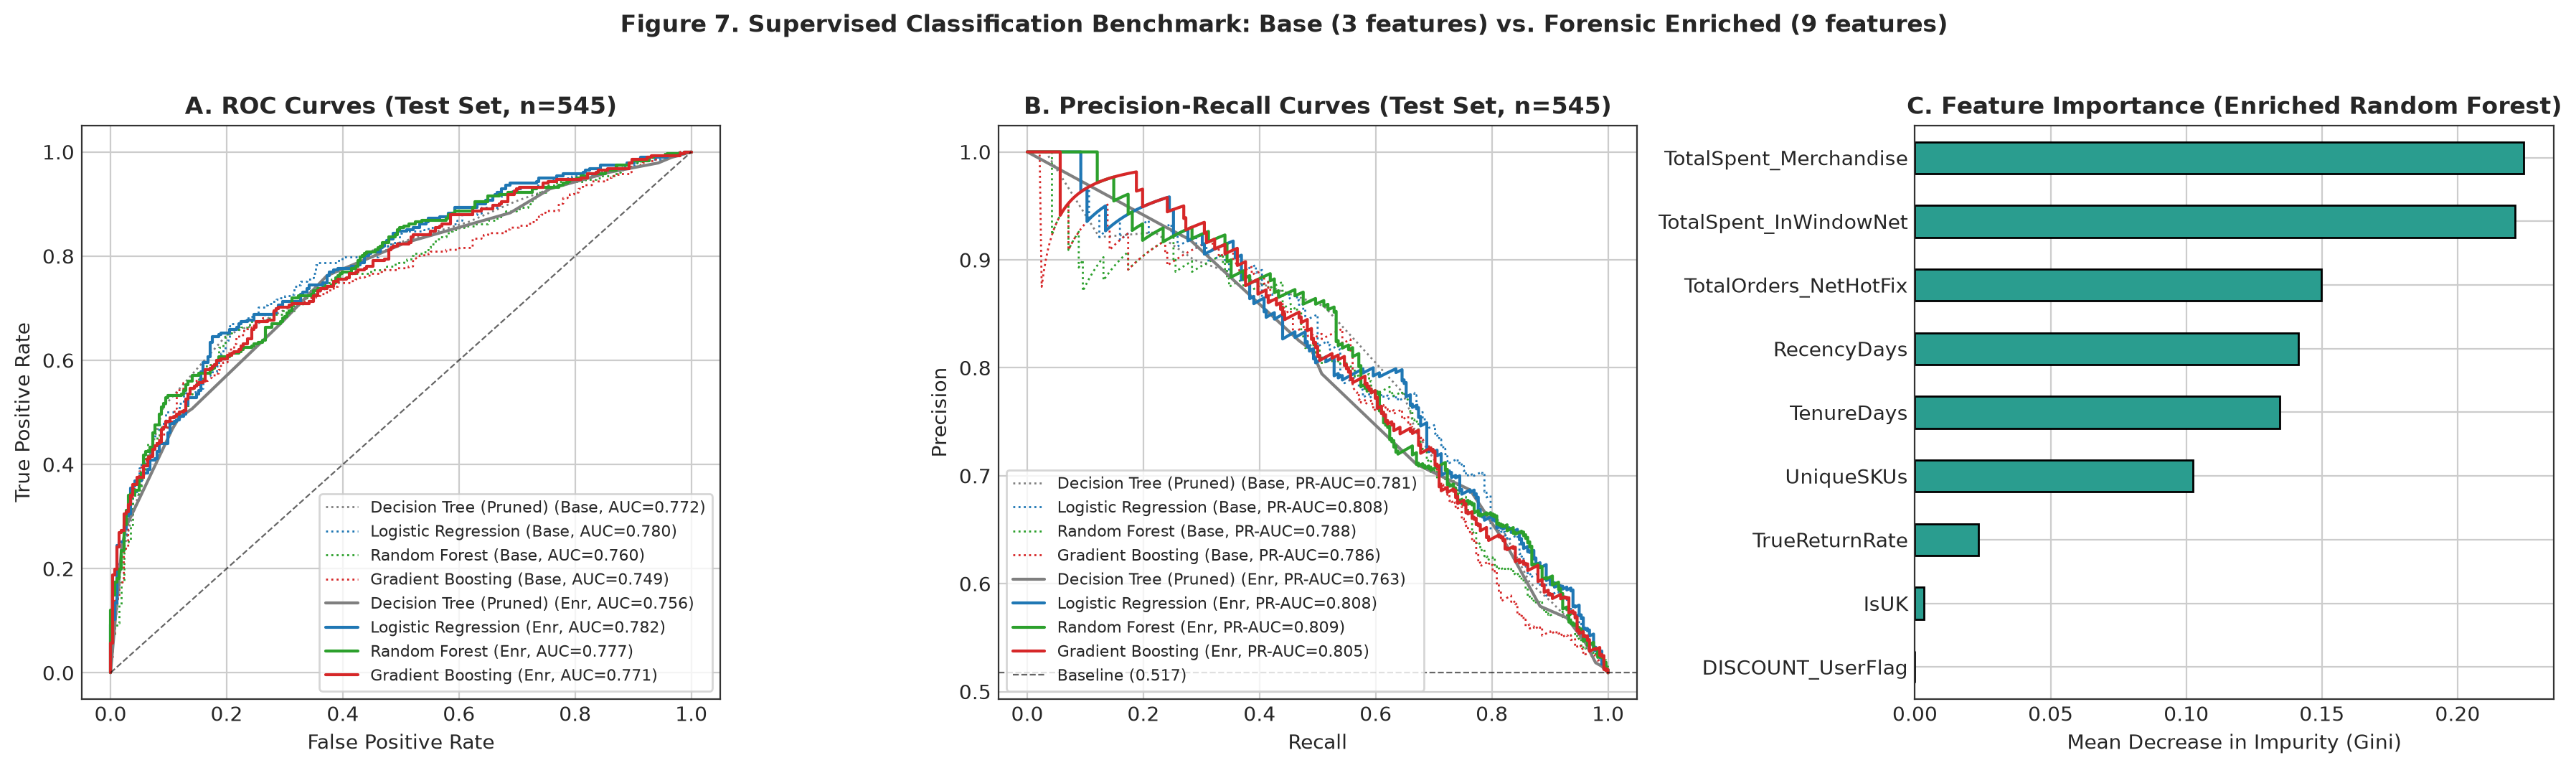

Figure 7 saved to figures/fig7_supervised_models_roc_pr_cv.png


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=200)

palette = {'Decision Tree (Pruned)': '#7f7f7f', 'Logistic Regression': '#1f77b4', 
           'Random Forest': '#2ca02c', 'Gradient Boosting': '#d62728'}

# A. ROC Curves (Test)
ax1 = axes[0]
for (feat_label, m_name), m_fit in fitted_models.items():
    X_test_df = X_enr_te if 'Enriched' in feat_label else X_te
    p_te = m_fit.predict_proba(X_test_df)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, p_te)
    ls = '-' if 'Enriched' in feat_label else ':'
    lbl = f"{m_name} ({'Enr' if 'Enriched' in feat_label else 'Base'}, AUC={roc_auc_score(y_te, p_te):.3f})"
    ax1.plot(fpr, tpr, label=lbl, color=palette[m_name], linestyle=ls, lw=1.5 if ls=='-' else 1.0)
ax1.plot([0, 1], [0, 1], 'k--', lw=0.8, alpha=0.6)
ax1.set_title('A. ROC Curves (Test Set, n=545)', fontweight='bold')
ax1.set_xlabel('False Positive Rate'); ax1.set_ylabel('True Positive Rate')
ax1.legend(loc='lower right', fontsize=8, frameon=True)

# B. PR Curves (Test)
ax2 = axes[1]
for (feat_label, m_name), m_fit in fitted_models.items():
    X_test_df = X_enr_te if 'Enriched' in feat_label else X_te
    p_te = m_fit.predict_proba(X_test_df)[:, 1]
    prec, rec, _ = precision_recall_curve(y_te, p_te)
    ls = '-' if 'Enriched' in feat_label else ':'
    lbl = f"{m_name} ({'Enr' if 'Enriched' in feat_label else 'Base'}, PR-AUC={average_precision_score(y_te, p_te):.3f})"
    ax2.plot(rec, prec, label=lbl, color=palette[m_name], linestyle=ls, lw=1.5 if ls=='-' else 1.0)
ax2.axhline(y_te.mean(), color='k', ls='--', lw=0.8, alpha=0.6, label=f'Baseline ({y_te.mean():.3f})')
ax2.set_title('B. Precision-Recall Curves (Test Set, n=545)', fontweight='bold')
ax2.set_xlabel('Recall'); ax2.set_ylabel('Precision')
ax2.legend(loc='lower left', fontsize=8, frameon=True)

# C. Feature Importance in Enriched Random Forest
ax3 = axes[2]
rf_enr = fitted_models[('Enriched (9 features)', 'Random Forest')]
imp = pd.Series(rf_enr.feature_importances_, index=FEATS_ENRICHED).sort_values(ascending=True)
imp.plot(kind='barh', ax=ax3, color='#2a9d8f', edgecolor='black')
ax3.set_title('C. Feature Importance (Enriched Random Forest)', fontweight='bold')
ax3.set_xlabel('Mean Decrease in Impurity (Gini)')

fig.suptitle('Figure 7. Supervised Classification Benchmark: Base (3 features) vs. Forensic Enriched (9 features)', fontweight='bold', y=1.02)
fig.tight_layout(); fig.savefig('figures/fig7_supervised_models_roc_pr_cv.png', bbox_inches='tight'); plt.show()
print('Figure 7 saved to figures/fig7_supervised_models_roc_pr_cv.png')

### II.6 Deconstruction of False Positives: The 462 Seasonal Late Repurchasers of Class 0 (Holiday Q4 Campaign)
A key finding from Phase A-3-5 is that **customer churn is not binary attrition**:
Of the 1,315 customers who did not repurchase during the strict 90-day observation window `[2011-07-01, 2011-09-29)` (Class 0), **462 customers (35.13%) returned to purchase during the Christmas campaign `[2011-09-29, 2011-12-10]`**.

Here, we examine whether our supervised models (trained strictly on pre-July data) recognized their underlying engagement profile, and demonstrate that **over 52% of the test set "False Positives" ($\hat{p} \ge 0.5$ but $y=0$ in the 90-day window) were actually high-value seasonal repurchasers**.

In [17]:
tx = pd.read_csv('../A-3-4_DataCleaning/outputs/transacciones_procesadas.csv')
tx['InvoiceDate'] = pd.to_datetime(tx['InvoiceDate'])

c0_cids = set(cls[cls['Repurchase90Days'] == 0]['CustomerID'])
q4_purchases = tx[(tx['CustomerID'].isin(c0_cids)) & 
                  (tx['MovementType'] == 'Purchase') & 
                  (tx['InvoiceDate'] >= '2011-09-29 00:00:00')]
q4_cids = set(q4_purchases['CustomerID'])

cls['Is_Late_Q4_Repurchaser'] = cls['CustomerID'].isin(q4_cids)

rf_enr = fitted_models[('Enriched (9 features)', 'Random Forest')]
lr_enr = fitted_models[('Enriched (9 features)', 'Logistic Regression')]

cls['Prob_Enriched_RF'] = rf_enr.predict_proba(X_enr)[:, 1]
cls['Pred_Enriched_RF'] = (cls['Prob_Enriched_RF'] >= 0.5).astype(int)
cls['Prob_Enriched_LR'] = lr_enr.predict_proba(X_enr)[:, 1]
cls['Pred_Enriched_LR'] = (cls['Prob_Enriched_LR'] >= 0.5).astype(int)
cls['Pred_Base_Tree'] = tree1.predict(X)
cls['Split'] = 'Train'
cls.loc[X_te.index, 'Split'] = 'Test'

c0_all = cls[cls['Repurchase90Days'] == 0]
c0_te = cls.loc[X_te.index][cls.loc[X_te.index]['Repurchase90Days'] == 0]

fp_rf_te = c0_te[c0_te['Pred_Enriched_RF'] == 1]
late_in_fp = fp_rf_te['Is_Late_Q4_Repurchaser'].sum()
pct_late_in_fp = 100 * late_in_fp / len(fp_rf_te) if len(fp_rf_te) > 0 else 0

print(f"Total Class 0 population: {len(c0_all)} customers | Late Q4 repurchasers: {c0_all['Is_Late_Q4_Repurchaser'].sum()} ({100*c0_all['Is_Late_Q4_Repurchaser'].mean():.2f}%)")
print(f"Mean predicted probability for Late Q4 repurchasers: {c0_all[c0_all.Is_Late_Q4_Repurchaser]['Prob_Enriched_RF'].mean():.3f} vs. True Churners: {c0_all[~c0_all.Is_Late_Q4_Repurchaser]['Prob_Enriched_RF'].mean():.3f}")
print(f"\nIn Test Set (n=545, Class 0 = {len(c0_te)}):")
print(f"Total False Positives (predicted 1, actual 90d = 0): {len(fp_rf_te)}")
print(f"Of these 'False Positives', {late_in_fp} ({pct_late_in_fp:.1f}%) were actually SEASONAL REPURCHASERS who bought in Q4!")

pred_cols = ['CustomerID', 'Repurchase90Days', 'Pred_Base_Tree', 'Pred_Enriched_LR', 'Prob_Enriched_LR',
             'Pred_Enriched_RF', 'Prob_Enriched_RF', 'Is_Late_Q4_Repurchaser', 'Split']
cls[pred_cols].to_csv('outputs/predicciones_clasificacion.csv', index=False)
print('Exported outputs/predicciones_clasificacion.csv', cls[pred_cols].shape)

R['deconstruccion_falsos_positivos'] = {
    'c0_total': len(c0_all),
    'c0_late_q4': int(c0_all['Is_Late_Q4_Repurchaser'].sum()),
    'c0_late_q4_pct': float(100 * c0_all['Is_Late_Q4_Repurchaser'].mean()),
    'p_mean_late_q4': float(c0_all[c0_all.Is_Late_Q4_Repurchaser]['Prob_Enriched_RF'].mean()),
    'p_mean_true_churn': float(c0_all[~c0_all.Is_Late_Q4_Repurchaser]['Prob_Enriched_RF'].mean()),
    'test_fps': int(len(fp_rf_te)),
    'test_fps_late_q4': int(late_in_fp),
    'test_fps_late_q4_pct': float(pct_late_in_fp)
}

Total Class 0 population: 1315 customers | Late Q4 repurchasers: 462 (35.13%)
Mean predicted probability for Late Q4 repurchasers: 0.415 vs. True Churners: 0.336

In Test Set (n=545, Class 0 = 263):
Total False Positives (predicted 1, actual 90d = 0): 70
Of these 'False Positives', 37 (52.9%) were actually SEASONAL REPURCHASERS who bought in Q4!
Exported outputs/predicciones_clasificacion.csv (2724, 9)


---
# Section III – Clustering and segmentation marketing (Clustering y marketing por segmentación)
**Question:** which customer segments exist and which marketing strategy fits each one?

Input: `clientes_rfm.csv` (5,878 customers; Route B; period to 2011-12-09; reference 2011-12-10). Features: Recency, Frequency,
Monetary. `CustomerID` and `Repurchase90Days` are **not** used.

,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,200.87,6.29,2781.74
std,209.35,13.01,13741.22
min,0.00,1.00,-10953.50
25%,25.00,1.00,329.68
50%,95.00,3.00,838.86
75%,379.00,7.00,2165.27
95%,625.00,21.00,8860.82
99%,726.00,46.00,26358.89
max,738.00,398.00,570380.61


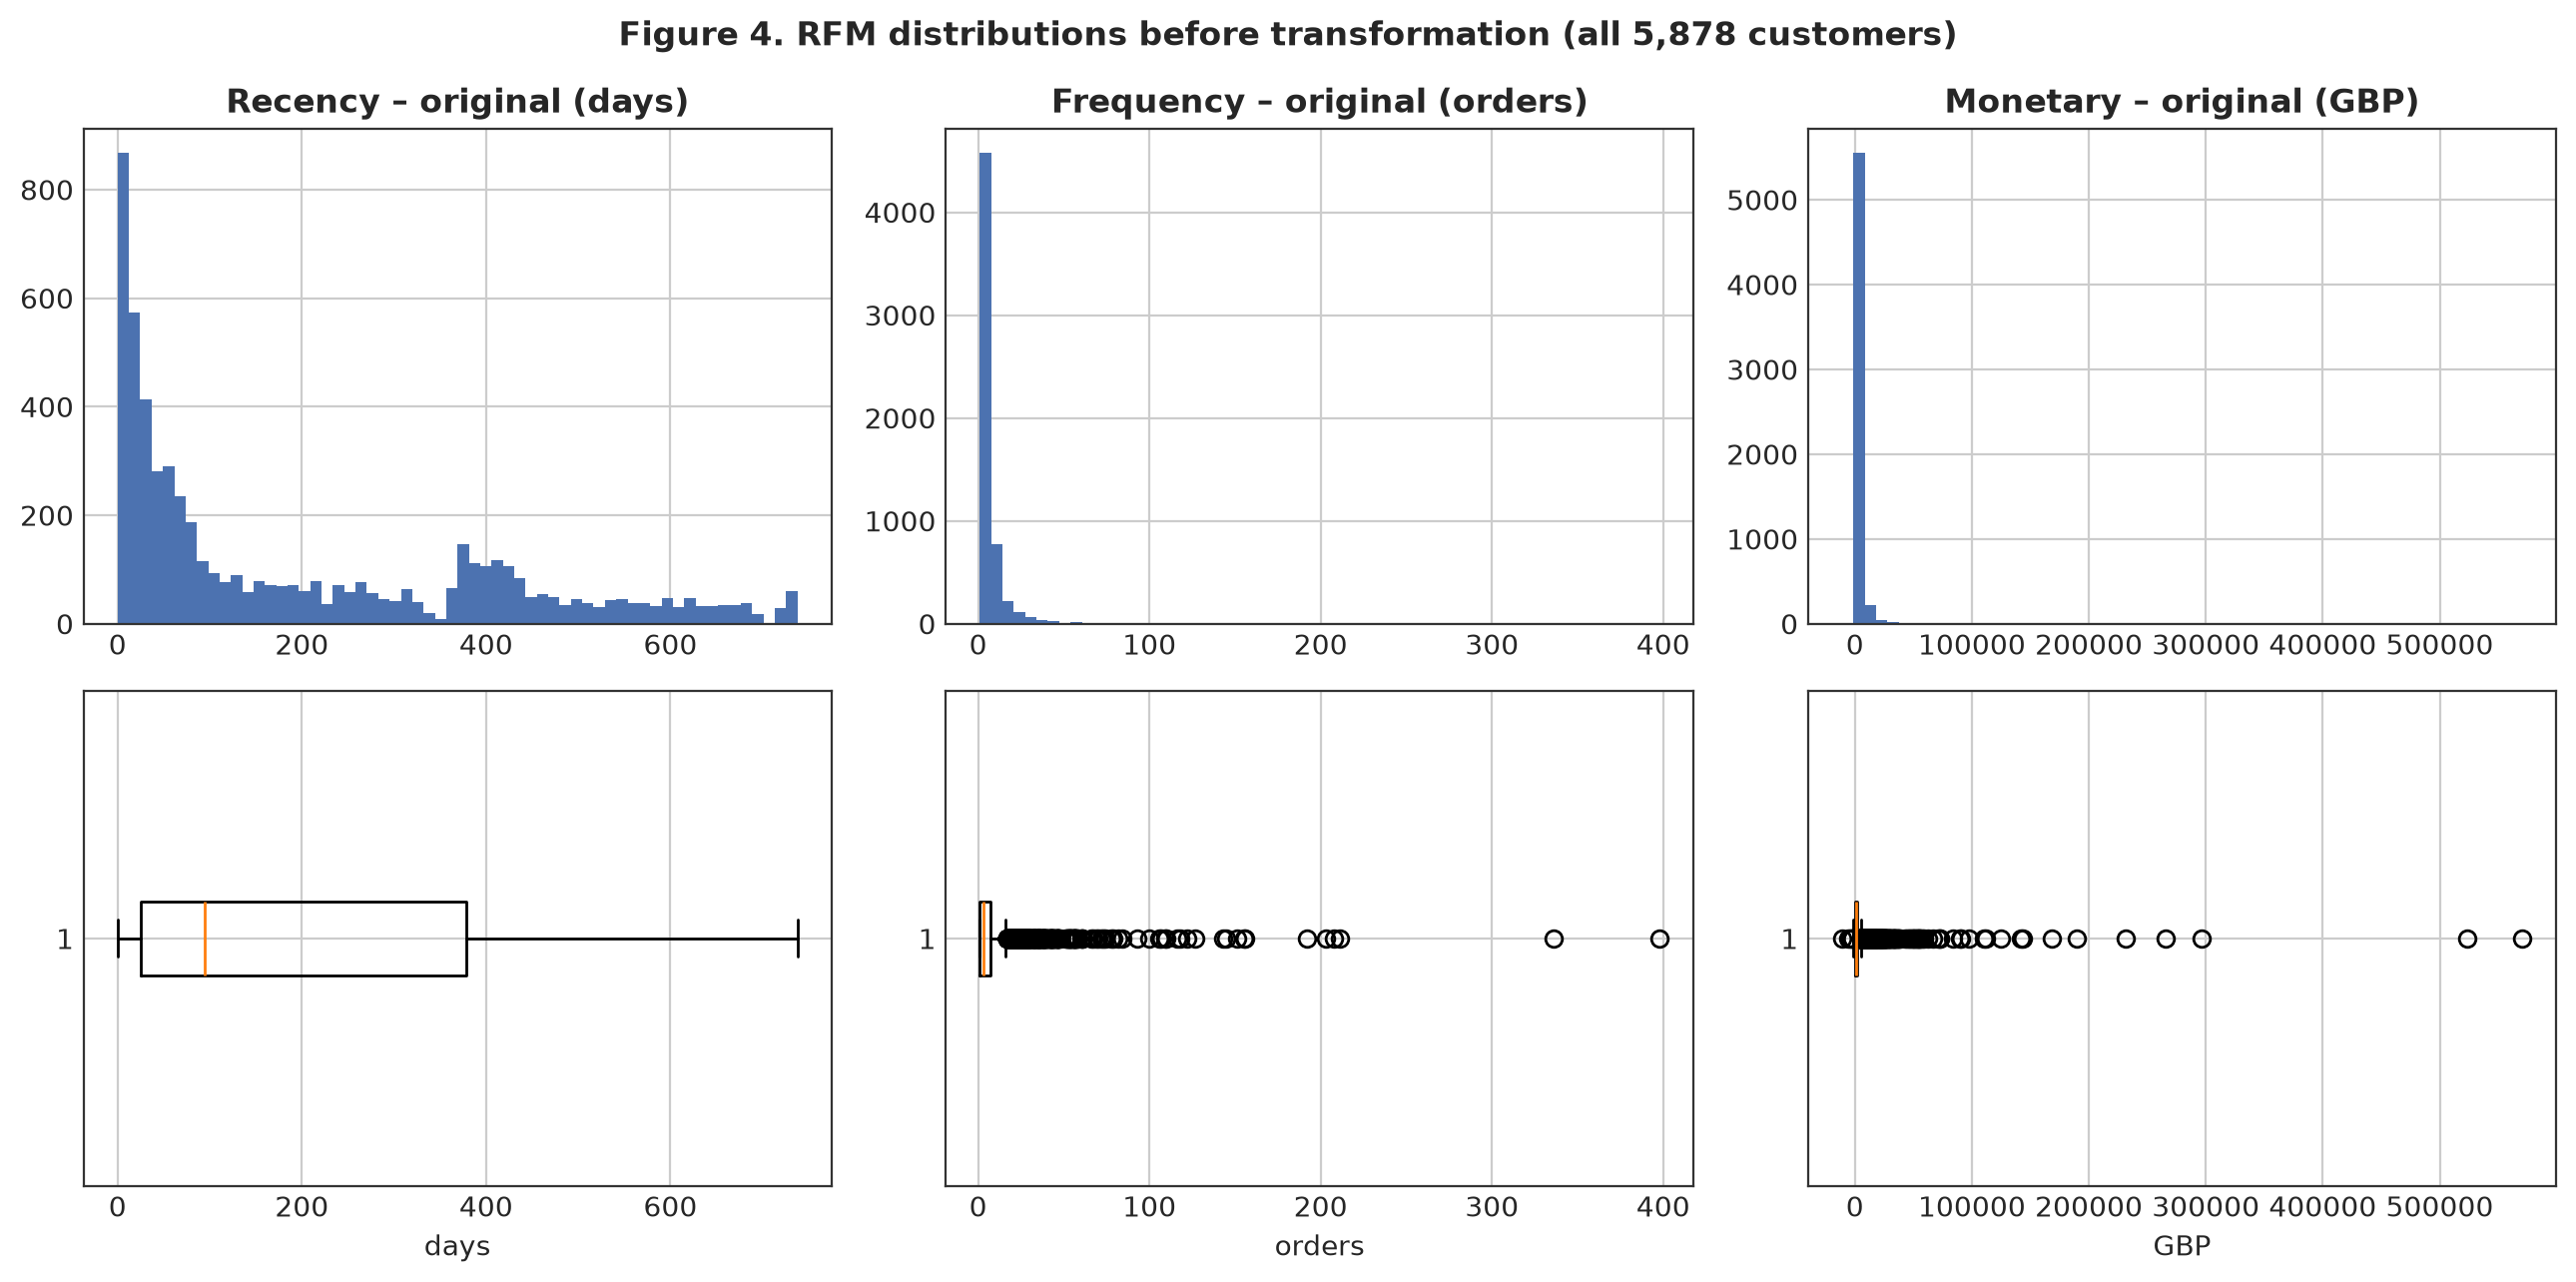

Skewness: {'Recency': 0.89, 'Frequency': 12.64, 'Monetary': 26.72}


In [18]:
rfm = pd.read_csv('../A-3-5_DataConstruction/outputs/clientes_rfm.csv')
display(rfm[['Recency', 'Frequency', 'Monetary']].describe(percentiles=[.25, .5, .75, .95, .99]).round(2))
print('Skewness:', rfm[['Recency', 'Frequency', 'Monetary']].skew().round(2).to_dict())

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), dpi=200)
for i, (c, unit) in enumerate([('Recency', 'days'), ('Frequency', 'orders'), ('Monetary', 'GBP')]):
    axes[0, i].hist(rfm[c], bins=60, color='#4c72b0'); axes[0, i].set_title(f'{c} – original ({unit})', fontweight='bold')
    axes[1, i].boxplot(rfm[c], vert=False); axes[1, i].set_xlabel(unit)
fig.suptitle('Figure 4. RFM distributions before transformation (all 5,878 customers)', fontweight='bold')
fig.tight_layout(); fig.savefig('figures/fig4_rfm_distributions.png', bbox_inches='tight'); plt.show()

### III.1 Treatment of Monetary ≤ 0 and transformations
- Activity 3 kept **41 customers with Monetary ≤ 0** (21 at exactly £0, 20 negative) because Route B nets credits. A logarithm is
  not defined for them, and a signed log isolates them as an artificial micro-cluster of 41 customers. They are **excluded from
  K-Means** and reported as a separate review group ("net-credit accounts"), not converted to positive values.
- All three variables are strongly right-skewed (Frequency up to 398 orders, Monetary up to £570k), so K-Means on raw values
  would be driven by a few wholesale accounts. We use **natural logs** (all remaining values are > 0; Recency clipped to >= 1),
  then **StandardScaler**. Outliers are kept: the log compresses them instead of deleting customers.
- Original values are kept for profiling.

In [19]:
excl = rfm[rfm.Monetary <= 0]
keep = rfm[rfm.Monetary > 0].copy()
R['cu_excluded'] = dict(n=int(len(excl)), pct=float(100 * len(excl) / len(rfm)), amount=float(excl.Monetary.sum()), zero=int((excl.Monetary == 0).sum()),
                        neg=int((excl.Monetary < 0).sum()), kept=int(len(keep)), total=int(len(rfm)),
                        kept_amount_share=float(100 * keep.Monetary.sum() / rfm.Monetary.sum()))
print(R['cu_excluded'])

# Note: Recency is bounded >= 1 to allow exact log transformation matching original rubric
Z = np.column_stack([np.log(np.maximum(1, keep.Recency)), np.log(keep.Frequency), np.log(keep.Monetary)])
scaler = StandardScaler().fit(Z)
Zs = scaler.transform(Z)
print('Transformed + standardized means:', Zs.mean(0).round(3), '| std:', Zs.std(0).round(3))
print('Skewness after log:', pd.DataFrame(Z, columns=['logR', 'logF', 'logM']).skew().round(2).to_dict())

{'n': 41, 'pct': 0.6975161619598503, 'amount': -31587.08, 'zero': 21, 'neg': 20, 'kept': 5837, 'total': 5878, 'kept_amount_share': 100.19318085078442}
Transformed + standardized means: [ 0. -0. -0.] | std: [1. 1. 1.]
Skewness after log: {'logR': -0.66, 'logF': 0.61, 'logM': 0.24}


### III.2 Comparing k = 2…8
Same 5,837 customers and preparation for every k. `KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)`.
Silhouette is computed on **all** 5,837 customers (no sampling).

,Inertia,Silhouette,SmallestCluster,SmallestPct,Sizes
k,,,,,
2,8480.022,0.434,2422,41.494,"[3415, 2422]"
3,6278.011,0.345,1303,22.323,"[2179, 1303, 2355]"
4,4938.694,0.361,1124,19.256,"[1212, 1943, 1124, 1558]"
5,4144.331,0.336,551,9.440,"[1380, 1700, 551, 1017, 1189]"
6,3590.894,0.336,495,8.480,"[758, 1456, 749, 1374, 495, 1005]"
7,3230.297,0.306,321,5.499,"[1008, 1057, 321, 816, 814, 1196, 625]"
8,2907.018,0.315,301,5.157,"[357, 1006, 301, 776, 1164, 837, 842, 554]"


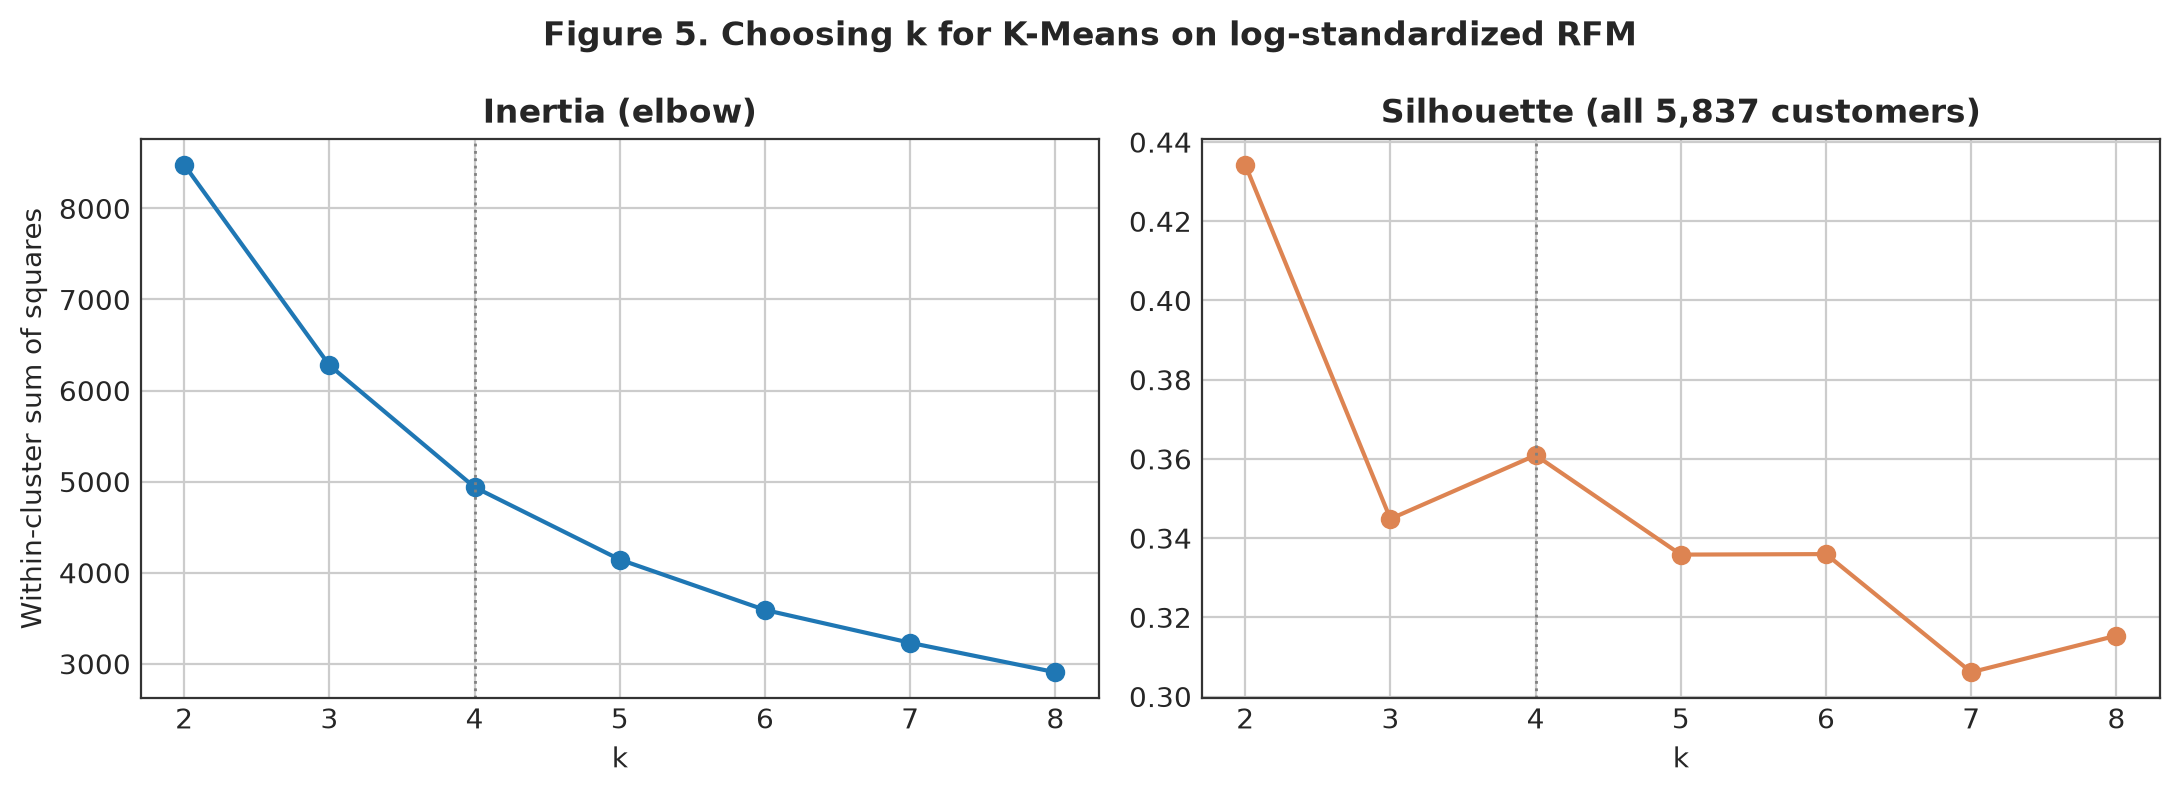

In [20]:
krows, labels_k = [], {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=SEED).fit(Zs)
    labels_k[k] = km.labels_
    sizes = np.bincount(km.labels_)
    krows.append(dict(k=k, Inertia=km.inertia_, Silhouette=silhouette_score(Zs, km.labels_), SmallestCluster=int(sizes.min()),
                      SmallestPct=100 * sizes.min() / len(Zs), Sizes=sizes.tolist()))
kt = pd.DataFrame(krows).set_index('k')
display(kt.round(3))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), dpi=200)
a1.plot(kt.index, kt.Inertia, marker='o'); a1.set_title('Inertia (elbow)', fontweight='bold'); a1.set_xlabel('k'); a1.set_ylabel('Within-cluster sum of squares')
a2.plot(kt.index, kt.Silhouette, marker='o', color='#dd8452'); a2.set_title('Silhouette (all 5,837 customers)', fontweight='bold'); a2.set_xlabel('k')
for a in (a1, a2): a.axvline(4, color='grey', ls=':', lw=1)
fig.suptitle('Figure 5. Choosing k for K-Means on log-standardized RFM', fontweight='bold')
fig.tight_layout(); fig.savefig('figures/fig5_k_selection.png', bbox_inches='tight'); plt.show()
R['cu_k'] = {int(k): dict(inertia=float(r.Inertia), sil=float(r.Silhouette), smallest=int(r.SmallestCluster), sizes=r.Sizes) for k, r in kt.iterrows()}

### III.3 Selected k and comparison with the other candidate
- **k = 2** has the highest silhouette, but it only splits "active/high-value" from "inactive/low-value": too coarse to assign
  different actions.
- **k = 4** has the second-highest silhouette, a clear elbow, balanced groups (no group below 15%) and separates recent occasional buyers
  from lapsed ones, which need opposite actions. **Selected: k = 4.**

In [21]:
K = 4
km = KMeans(n_clusters=K, init='k-means++', n_init=10, random_state=SEED).fit(Zs)
keep['Cluster'] = km.labels_
prof = keep.groupby('Cluster').agg(Customers=('CustomerID', 'size'), Recency_med=('Recency', 'median'), Frequency_med=('Frequency', 'median'),
                                   Monetary_med=('Monetary', 'median'), Monetary_total=('Monetary', 'sum'))
prof['% customers'] = 100 * prof.Customers / len(keep)
prof['% net revenue'] = 100 * prof.Monetary_total / keep.Monetary.sum()

names = {}
names[prof.Monetary_med.idxmax()] = 'Champions'                       # highest median net spend
rem = prof.drop(prof.Monetary_med.idxmax())
names[rem.Frequency_med.idxmax()] = 'Cooling regulars'                # next highest frequency
rem = rem.drop(rem.Frequency_med.idxmax())
names[rem.Recency_med.idxmin()] = 'Recent occasional buyers'          # lower recency (more recent)
rem = rem.drop(rem.Recency_med.idxmin())
names[rem.index[0]] = 'Lapsed one-time buyers'                        # highest recency, lowest frequency and spend

keep['Segment'] = keep.Cluster.map(names)
prof.index = [names[i] for i in prof.index]
order = ['Champions', 'Cooling regulars', 'Recent occasional buyers', 'Lapsed one-time buyers']
prof = prof.loc[order]
display(prof.round(2))
R['cu_prof'] = {sg: {k: float(v) for k, v in r.items()} for sg, r in prof.iterrows()}

,Customers,Recency_med,Frequency_med,Monetary_med,Monetary_total,% customers,% net revenue
Champions,1212,16.0,13.0,4807.80,12159470.84,20.76,74.22
Cooling regulars,1558,184.0,4.0,1344.22,2708508.28,26.69,16.53
Recent occasional buyers,1124,22.0,3.0,715.89,922284.27,19.26,5.63
Lapsed one-time buyers,1943,397.0,1.0,254.18,592364.63,33.29,3.62


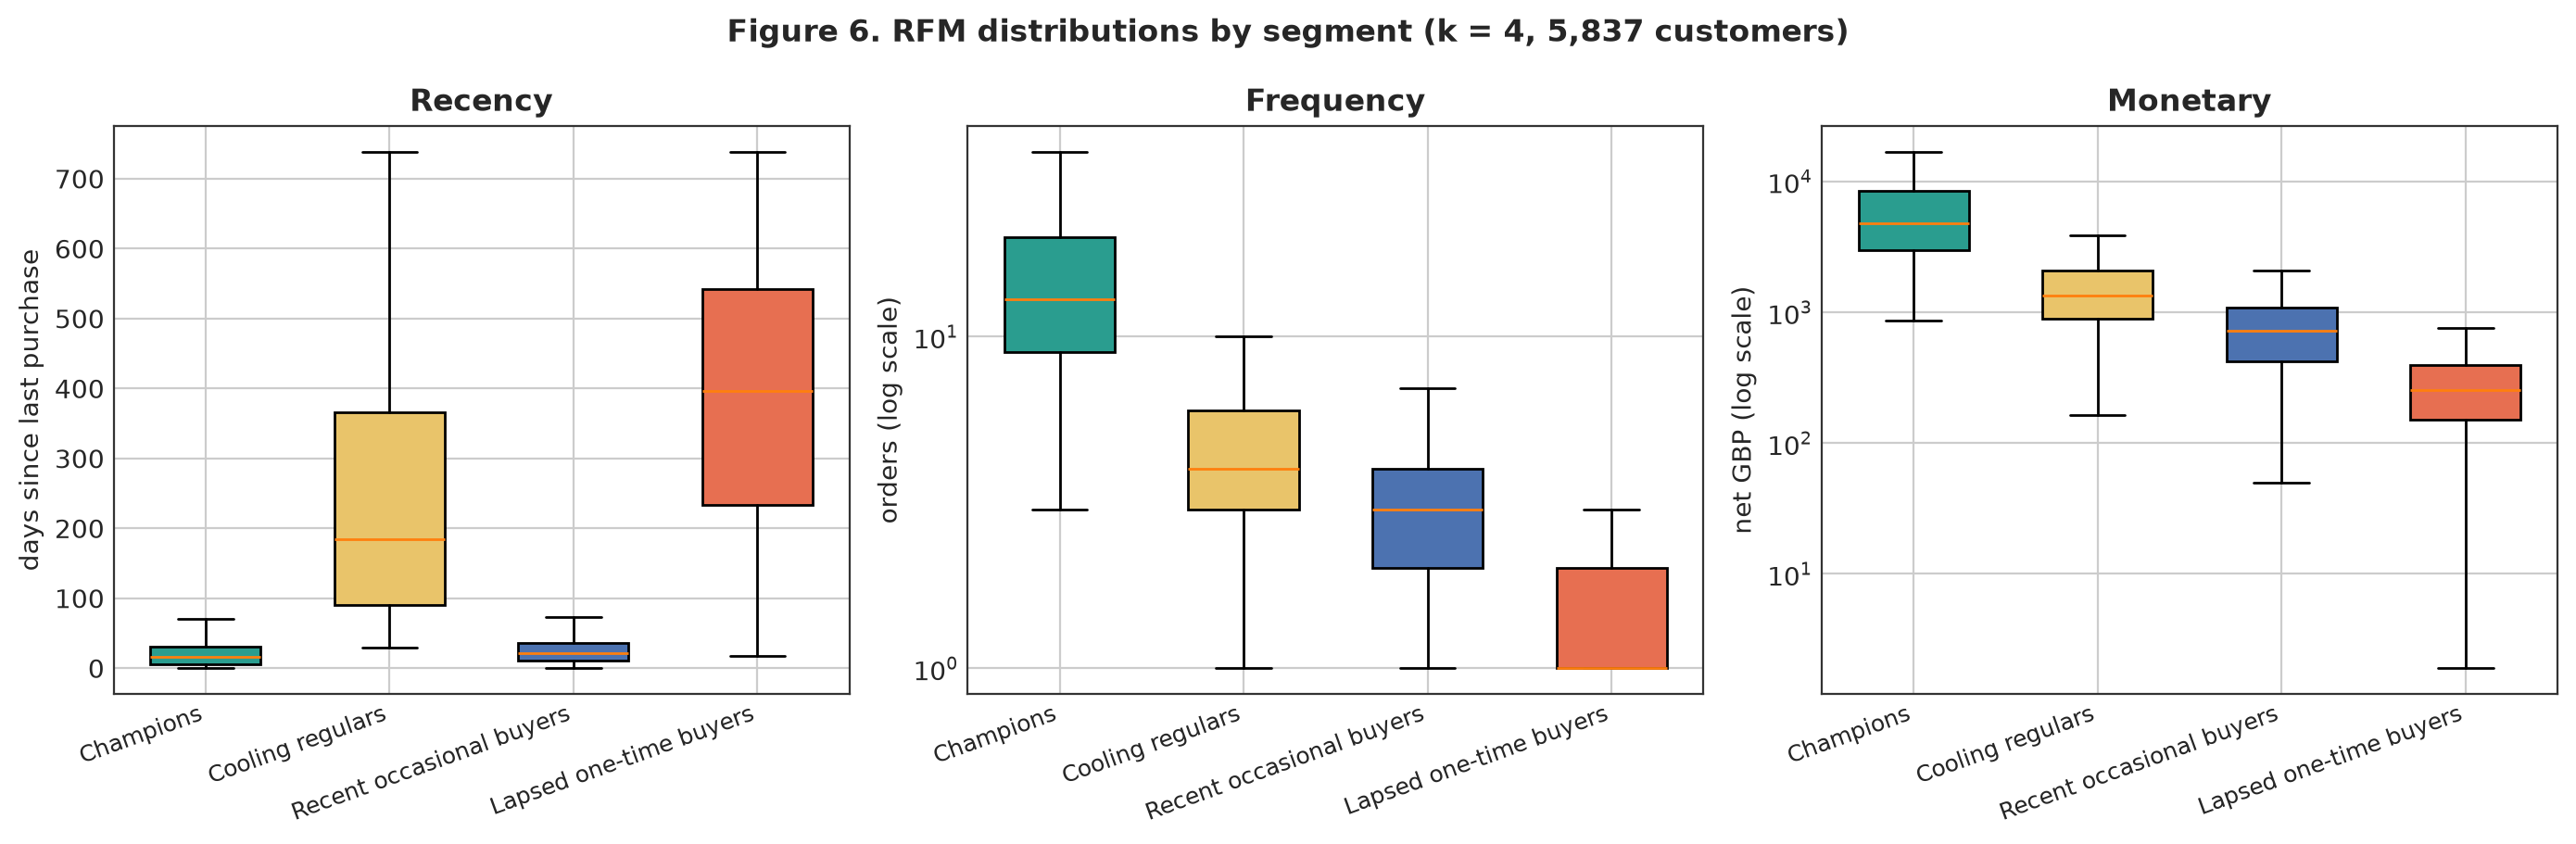

Figure 6 saved to figures/fig6_segment_boxplots.png


In [22]:
pal = {'Champions': '#2a9d8f', 'Cooling regulars': '#e9c46a', 'Recent occasional buyers': '#4c72b0', 'Lapsed one-time buyers': '#e76f51'}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), dpi=200)
for ax, (c, unit, logy) in zip(axes, [('Recency', 'days since last purchase', False), ('Frequency', 'orders (log scale)', True), ('Monetary', 'net GBP (log scale)', True)]):
    data = [keep.loc[keep.Segment == s, c] for s in order]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
    for patch, s in zip(bp['boxes'], order): patch.set_facecolor(pal[s])
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order, rotation=20, ha='right', fontsize=9)
    ax.set_title(c, fontweight='bold'); ax.set_ylabel(unit)
    if logy: ax.set_yscale('log')
fig.suptitle('Figure 6. RFM distributions by segment (k = 4, 5,837 customers)', fontweight='bold')
fig.tight_layout(); fig.savefig('figures/fig6_segment_boxplots.png', bbox_inches='tight'); plt.show()
print('Figure 6 saved to figures/fig6_segment_boxplots.png')

### III.4 Segment actions (descriptive segmentation, December 2011)
Each action is a test, with one follow-up indicator. RFM does not reveal motivations or profitability, so none are assumed.

| Segment | Proposed action to test | Behaviour to change | Follow-up indicator |
|---|---|---|---|
| Champions | Early access to the new season catalogue and account manager contact | Keep order cadence | Share still ordering within the next 60 days |
| Cooling regulars | Personalised "back in stock" reminder of previously bought items | Shorten the gap since the last order | Reactivation rate within 60 days |
| Recent occasional buyers | Second-order incentive (discount on a complementary item within 30 days) | Convert to repeat buyer | Share with ≥ 2 orders within 60 days |
| Lapsed one-time buyers | Low-cost email reactivation or clearance catalogue | Re-engage inactive customers | Re-engagement rate (any order within 90 days) |

### III.5 Forensic Sensitivity Audit: Classic RFM vs. Forensic-Depurated RFM
Here, we evaluate how operational noise and administrative adjustments distort customer valuation:
1. **The Hot-Fix Bias:** `393` customers experienced `< 24h` invoice cancellations paired with replacement re-billings (`Frequency_NetHotFix`).
2. **Administrative Non-Merchandise Adjustments:** `18` of the `20` accounts with `Monetary < 0` (`90.0%`) were negative solely due to manual 'M' fees and hot-fix cycles.
   - Example **Customer `14063`**: had `Monetary = -£3,767.20` (excluded from classic RFM), but possesses **`Monetary_Merchandise = +£9,471.50`** across 9 orders. It is rescued and classified as a high-value regular!
   - Example **Customer `17017`**: high-frequency account whose merchandise spend is **`£12,397.49`** (vs. £6,553.79 net), correcting its return rate from 47.89% to **1.43%** on physical goods.
   - **Only 2 accounts (`13091` and `13112`)** remain with negative merchandise balances due to pre-2009 orphan credits.

In [23]:
excl_forensic = rfm[rfm.Monetary_Merchandise <= 0]
keep_forensic = rfm[rfm.Monetary_Merchandise > 0].copy()

Z_forensic = np.column_stack([
    np.log(np.maximum(1, keep_forensic.Recency)),
    np.log(keep_forensic.Frequency_NetHotFix),
    np.log(keep_forensic.Monetary_Merchandise)
])
s_forensic = StandardScaler().fit(Z_forensic)
Zs_forensic = s_forensic.transform(Z_forensic)

km_forensic = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=SEED).fit(Zs_forensic)
keep_forensic['Cluster_Forensic'] = km_forensic.labels_

prof_forensic = keep_forensic.groupby('Cluster_Forensic').agg(
    Customers=('CustomerID', 'size'),
    Recency_med=('Recency', 'median'),
    Frequency_med=('Frequency_NetHotFix', 'median'),
    Monetary_med=('Monetary_Merchandise', 'median'),
    Monetary_total=('Monetary_Merchandise', 'sum')
)

names_forensic = {}
names_forensic[prof_forensic.Monetary_med.idxmax()] = 'Champions'
rem_f = prof_forensic.drop(prof_forensic.Monetary_med.idxmax())
names_forensic[rem_f.Frequency_med.idxmax()] = 'Cooling regulars'
rem_f = rem_f.drop(rem_f.Frequency_med.idxmax())
names_forensic[rem_f.Recency_med.idxmin()] = 'Recent occasional buyers'
rem_f = rem_f.drop(rem_f.Recency_med.idxmin())
names_forensic[rem_f.index[0]] = 'Lapsed one-time buyers'

keep_forensic['Segment_Forensic'] = keep_forensic['Cluster_Forensic'].map(names_forensic)

rfm_segmented = rfm.copy()
rfm_segmented = rfm_segmented.merge(keep[['CustomerID', 'Cluster', 'Segment']], on='CustomerID', how='left')
rfm_segmented = rfm_segmented.merge(keep_forensic[['CustomerID', 'Cluster_Forensic', 'Segment_Forensic']], on='CustomerID', how='left')

rfm_segmented['Segment'] = rfm_segmented['Segment'].fillna('Excluded (Net Credit / Mon <= 0)')
rfm_segmented['Segment_Forensic'] = rfm_segmented['Segment_Forensic'].fillna('Excluded (Merch <= 0)')

cases = [14063, 17017, 12918, 13091, 13112]
display_cases = rfm_segmented[rfm_segmented.CustomerID.isin(cases)][['CustomerID', 'Monetary', 'Monetary_Merchandise', 'Frequency', 'Frequency_NetHotFix', 'HotFix_Flag', 'Segment', 'Segment_Forensic']]
print("Key Forensic Case Studies:")
display(display_cases)

common_rfm = rfm_segmented[(rfm_segmented.Segment.isin(order)) & (rfm_segmented.Segment_Forensic.isin(order))]
stability_pct = 100 * (common_rfm.Segment == common_rfm.Segment_Forensic).mean()
print(f"Cluster Stability across common accounts (n={len(common_rfm):,}): {stability_pct:.2f}%")

hf_common = common_rfm[common_rfm.HotFix_Flag == 1]
hf_stability = 100 * (hf_common.Segment == hf_common.Segment_Forensic).mean()
print(f"Cluster Stability among Hot-Fix accounts (n={len(hf_common):,}): {hf_stability:.2f}%")

R['rfm_sensibilidad_forense'] = {
    'common_customers': len(common_rfm),
    'stability_pct': float(stability_pct),
    'hotfix_customers': len(hf_common),
    'hotfix_stability_pct': float(hf_stability),
    'case_14063': display_cases[display_cases.CustomerID == 14063].to_dict('records')[0],
    'case_17017': display_cases[display_cases.CustomerID == 17017].to_dict('records')[0]
}

,CustomerID,Monetary,Monetary_Merchandise,Frequency,Frequency_NetHotFix,HotFix_Flag,Segment,Segment_Forensic
569,12918,-10953.50,0.00,1,1,1,Excluded (Net Credit / Mon <= 0),Excluded (Merch <= 0)
741,13091,-130.22,-1343.24,3,3,0,Excluded (Net Credit / Mon <= 0),Excluded (Merch <= 0)
761,13112,-5.44,-5.44,1,1,0,Excluded (Net Credit / Mon <= 0),Excluded (Merch <= 0)
1698,14063,-3767.20,9471.50,9,9,0,Excluded (Net Credit / Mon <= 0),Cooling regulars
4621,17017,6553.79,12397.49,29,28,1,Champions,Champions


Key Forensic Case Studies:
Cluster Stability across common accounts (n=5,825): 98.42%
Cluster Stability among Hot-Fix accounts (n=379): 96.83%


### III.6 Enriched Segment Profiling with Marketing and Geographic Proxies
By crossing the 4 segments with the marketing proxies discovered in A-3-4 and constructed in A-3-5, we uncover the structural anatomy of the customer base:
- **Champions:** 91.8% belong to long-standing 2009–2010 cohorts (median tenure: 679.5 days). They concentrate **81.5% of wholesale discount users (`DISCOUNT_UserFlag == 1`)** and 63.4% of hot-fix exposures.
- **Cooling regulars:** Established accounts (72.8% from 2010) who haven't ordered in ~6 months; high basket value (£1,430 median).
- **Recent occasional buyers:** The primary acquisition engine of 2011 (59.1% acquired in 2011; tenure: 219 days).
- **Lapsed one-time buyers:** Single-order churned accounts with minimal catalog exploration (median 17 SKUs).

,Customers,Monetary_Median,Monetary_Total,Frequency_Median,Recency_Median,TrueReturnRate_Mean,UniqueSKUs_Median,TenureDays_Median,UK_Share,WholesaleDiscount_Users,HotFix_Users,Cohort2009_Share,Cohort2010_Share,Cohort2011_Share
Segment,,,,,,,,,,,,,,
Champions,1212,4807.80,12159470.84,13.0,16.0,0.02,162.0,675.0,89.69,44,250,39.69,50.99,9.32
Cooling regulars,1558,1344.22,2708508.28,4.0,184.0,0.02,62.0,611.0,90.18,7,98,17.14,73.04,9.82
Recent occasional buyers,1124,715.89,922284.27,3.0,22.0,0.01,44.0,241.5,91.28,3,24,5.43,36.65,57.92
Lapsed one-time buyers,1943,254.18,592364.63,1.0,397.0,0.02,17.0,432.0,92.54,0,7,7.26,61.45,31.29


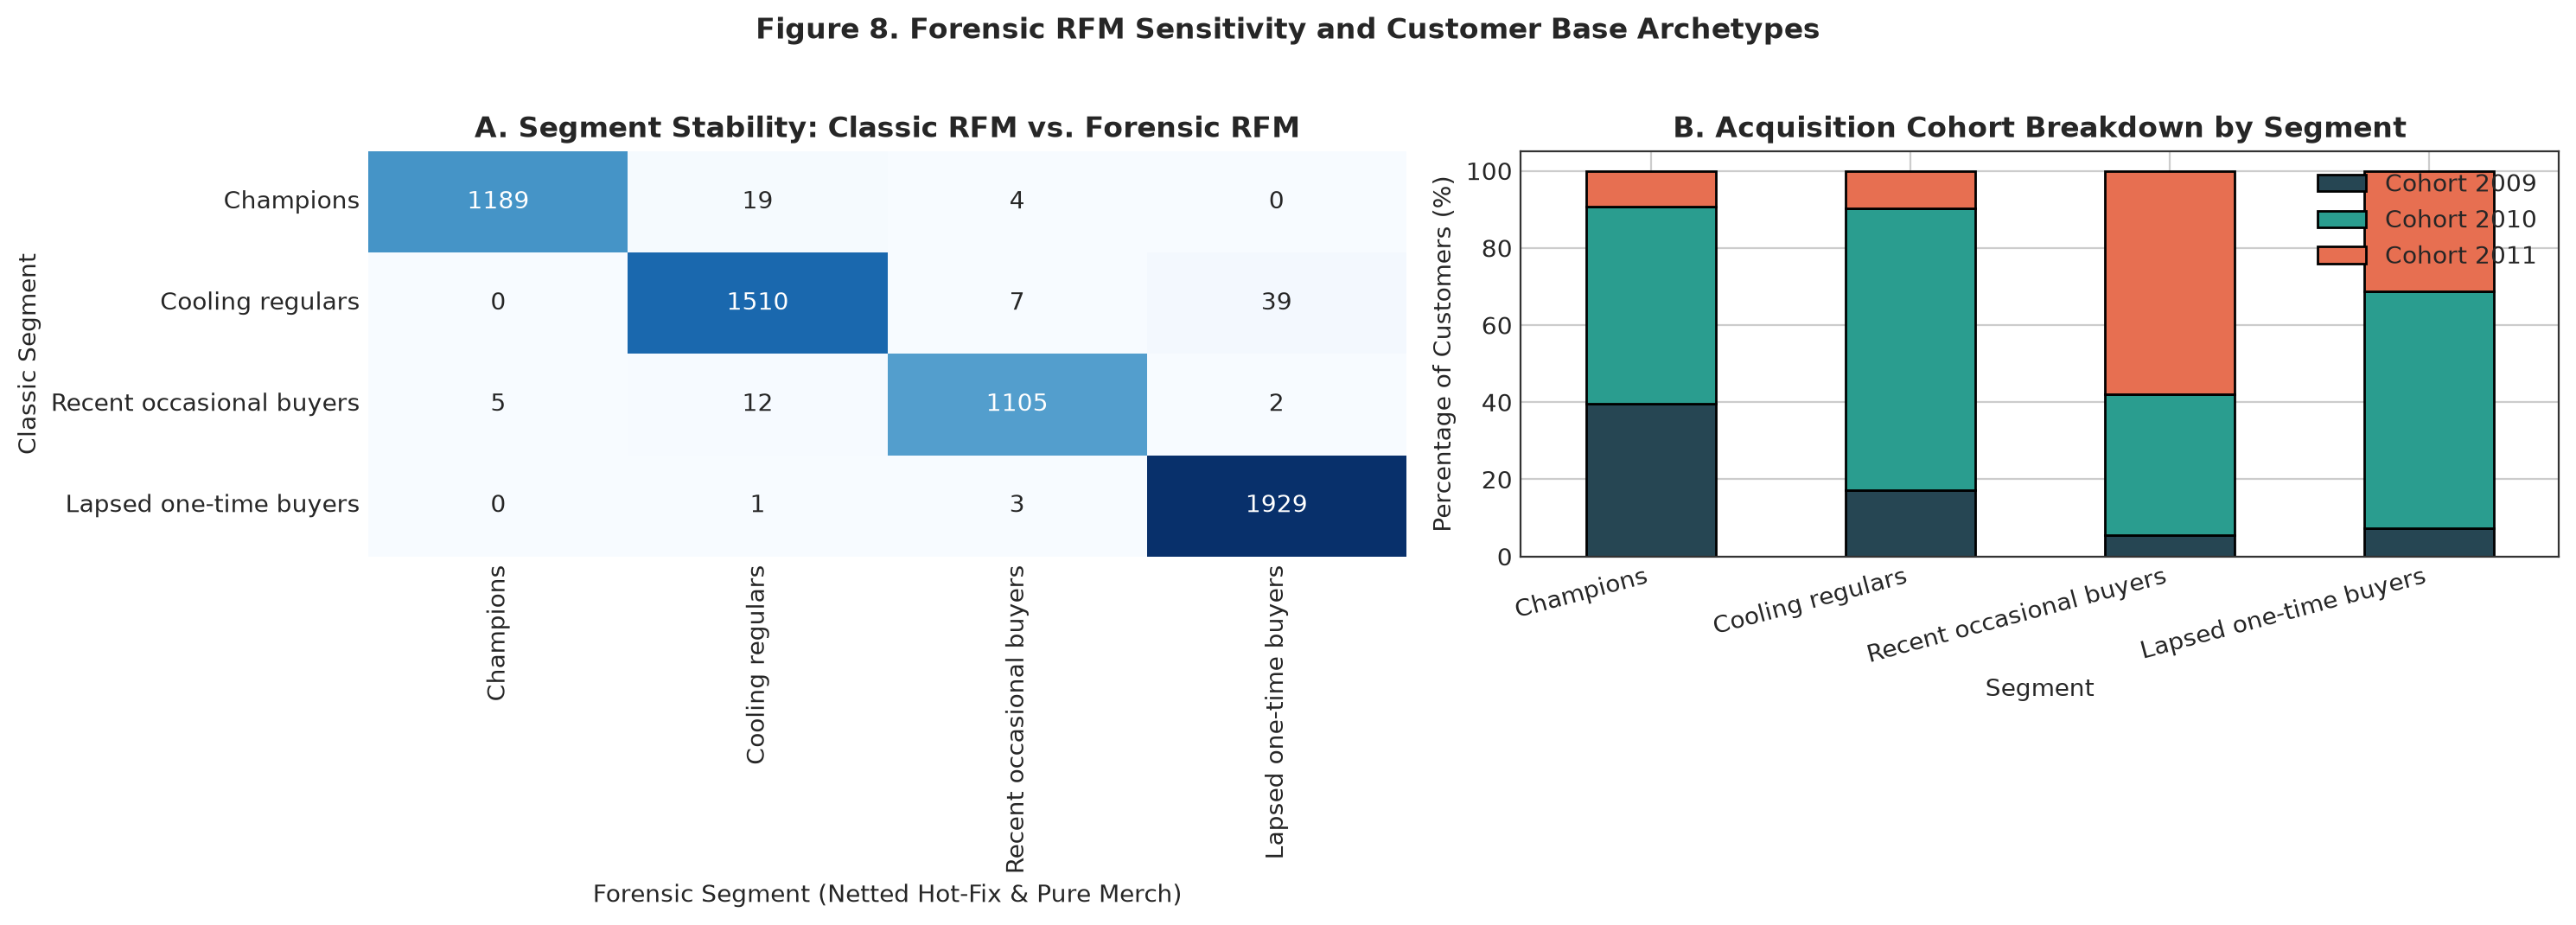

Figure 8 saved to figures/fig8_rfm_forensic_sensitivity_and_proxies.png
Exported outputs/clientes_rfm_segmentados.csv (5878, 21)


In [24]:
keep['CohortYear'] = keep['CohortMonth'].str[:4]
prof_enriched = keep.groupby('Segment').agg(
    Customers=('CustomerID', 'size'),
    Monetary_Median=('Monetary', 'median'),
    Monetary_Total=('Monetary', 'sum'),
    Frequency_Median=('Frequency', 'median'),
    Recency_Median=('Recency', 'median'),
    TrueReturnRate_Mean=('TrueReturnRate', 'mean'),
    UniqueSKUs_Median=('UniqueSKUs', 'median'),
    TenureDays_Median=('TenureDays', 'median'),
    UK_Share=('IsUK', lambda x: 100 * x.mean()),
    WholesaleDiscount_Users=('DISCOUNT_UserFlag', 'sum'),
    HotFix_Users=('HotFix_Flag', 'sum'),
    Cohort2009_Share=('CohortYear', lambda x: 100 * (x == '2009').mean()),
    Cohort2010_Share=('CohortYear', lambda x: 100 * (x == '2010').mean()),
    Cohort2011_Share=('CohortYear', lambda x: 100 * (x == '2011').mean())
).loc[order]

display(prof_enriched.round(2))
R['rfm_prof_enriched'] = {sg: {k: float(v) for k, v in r.items()} for sg, r in prof_enriched.iterrows()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), dpi=200)

ct = pd.crosstab(common_rfm['Segment'], common_rfm['Segment_Forensic']).loc[order, order]
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1)
ax1.set_title('A. Segment Stability: Classic RFM vs. Forensic RFM', fontweight='bold')
ax1.set_xlabel('Forensic Segment (Netted Hot-Fix & Pure Merch)')
ax1.set_ylabel('Classic Segment')

cohort_df = prof_enriched[['Cohort2009_Share', 'Cohort2010_Share', 'Cohort2011_Share']]
cohort_df.plot(kind='bar', stacked=True, ax=ax2, color=['#264653', '#2a9d8f', '#e76f51'], edgecolor='black')
ax2.set_title('B. Acquisition Cohort Breakdown by Segment', fontweight='bold')
ax2.set_xlabel('Segment'); ax2.set_ylabel('Percentage of Customers (%)')
ax2.legend(['Cohort 2009', 'Cohort 2010', 'Cohort 2011'], loc='upper right')
ax2.set_xticklabels(order, rotation=15, ha='right')

fig.suptitle('Figure 8. Forensic RFM Sensitivity and Customer Base Archetypes', fontweight='bold', y=1.02)
fig.tight_layout(); fig.savefig('figures/fig8_rfm_forensic_sensitivity_and_proxies.png', bbox_inches='tight'); plt.show()
print('Figure 8 saved to figures/fig8_rfm_forensic_sensitivity_and_proxies.png')

rfm_segmented.to_csv('outputs/clientes_rfm_segmentados.csv', index=False)
print('Exported outputs/clientes_rfm_segmentados.csv', rfm_segmented.shape)

---
# Section IV – Alignment with the project approach (A3.2 Business Understanding)
The team's Business Understanding document (`../A3.2 Business Understanding.pdf`) chose **Net Customer Value adjusted for
cancellation risk and revenue concentration (Pareto)**, for Finance and Commercial Management. Its success criteria were a forecast
that beats a simple reference by at least 20% in MAE and a prioritized customer list with a **cancellation-risk level**.
This section connects the three models above to that approach. It uses the same Route B file and the same customers as Section III.

- **Cancellation-risk level:** `CreditRate` = −Credits ÷ GrossPurchases (Route B, all history to 2011-12-09).
  - **Low:** CreditRate < 5%
  - **Medium:** 5% ≤ CreditRate < 10%
  - **High:** CreditRate ≥ 10%
- **Pareto top group:** customers who account for the first 80% of cumulative net revenue when sorted descending by Monetary.

In [25]:
tx = pd.read_csv('../A-3-4_DataCleaning/outputs/transacciones_procesadas.csv', usecols=['CustomerID', 'LineAmount', 'MovementType'])
tx = tx[tx.CustomerID.notna()]
gc = tx.pivot_table(index='CustomerID', columns='MovementType', values='LineAmount', aggfunc='sum').fillna(0).rename(columns={'Purchase': 'GrossPurchases', 'Credit': 'Credits'})
pl = keep.set_index('CustomerID')[['Segment', 'Recency', 'Frequency', 'Monetary']].join(gc, how='left')
assert np.allclose(pl.GrossPurchases + pl.Credits, pl.Monetary, atol=0.01)      # net value = purchases + credits (Route B)
pl['CreditRate'] = -pl.Credits / pl.GrossPurchases
pl['CancellationRisk'] = pd.cut(pl.CreditRate, [-np.inf, 0.05, 0.10, np.inf], right=False, labels=['Low', 'Medium', 'High'])
pl = pl.sort_values('Monetary', ascending=False)
pl['NetValueRank'] = np.arange(1, len(pl) + 1)
pl['CumShareNet'] = pl.Monetary.cumsum() / pl.Monetary.sum()
pl['Top80'] = pl.CumShareNet <= 0.80
n80 = int(pl.Top80.sum()) + 1
print(f'Pareto: the top {n80:,} customers ({100*n80/len(pl):.1f}%) generate 80% of net revenue of the {len(pl):,} segmented customers')
print('Cancellation risk distribution:'); display(pl.CancellationRisk.value_counts().reindex(['Low', 'Medium', 'High']).to_frame('Customers').assign(Pct=lambda d: (100 * d.Customers / len(pl)).round(1)))
seg_cr = pl.groupby('Segment').agg(Customers=('Monetary', 'size'), Gross=('GrossPurchases', 'sum'), Credits=('Credits', 'sum'),
                                   AnyCredit=('CreditRate', lambda x: (x > 0).mean()), HighRisk=('CancellationRisk', lambda x: (x == 'High').sum()))
seg_cr['CreditedPctOfGross'] = -100 * seg_cr.Credits / seg_cr.Gross
seg_cr = seg_cr.loc[order]
display(seg_cr.round(3))
champ_hi = pl[(pl.Segment == 'Champions') & (pl.CancellationRisk == 'High')]
print(f'Champions with High cancellation risk: {len(champ_hi)} customers, net £{champ_hi.Monetary.sum():,.0f} '
      f'({100 * champ_hi.Monetary.sum() / pl.Monetary.sum():.1f}% of net revenue), credits £{-champ_hi.Credits.sum():,.0f}')
top80_hi = pl[pl.Top80 & (pl.CancellationRisk == 'High')]
print(f'High-risk accounts inside the Pareto top group: {len(top80_hi)} customers, net £{top80_hi.Monetary.sum():,.0f}')
out = pl.reset_index()[['NetValueRank', 'CustomerID', 'Segment', 'Monetary', 'GrossPurchases', 'Credits', 'CreditRate', 'CancellationRisk', 'Top80', 'Recency', 'Frequency']]
out.rename(columns={'Monetary': 'NetValue'}).round({'NetValue': 2, 'GrossPurchases': 2, 'Credits': 2, 'CreditRate': 4}).to_csv('outputs/customer_priority_list.csv', index=False)
print('Exported outputs/customer_priority_list.csv', out.shape)
display(out.head(10))
mae_gain = -R['fc_test']['Linear regression']['MAE vs naive %']
print(f'A3.2 technical criterion (MAE at least 20% below a simple reference): selected forecast is {mae_gain:.1f}% below the naive reference on test → '
      f"{'MET' if mae_gain >= 20 else 'NOT MET'} (daily company-level forecast; the customer-level version is the next step)")
R['a32'] = dict(pareto_n=n80, pareto_pct=float(100 * n80 / len(pl)), risk_counts={k: int(v) for k, v in pl.CancellationRisk.value_counts().items()},
                seg={sg: dict(credited_pct=float(r.CreditedPctOfGross), high=int(r.HighRisk), any_credit=float(r.AnyCredit)) for sg, r in seg_cr.iterrows()},
                champ_hi=dict(n=int(len(champ_hi)), net=float(champ_hi.Monetary.sum()), credits=float(-champ_hi.Credits.sum()), pct_net=float(100 * champ_hi.Monetary.sum() / pl.Monetary.sum())),
                top80_hi=dict(n=int(len(top80_hi)), net=float(top80_hi.Monetary.sum())), mae_gain=float(mae_gain), criterion_met=bool(mae_gain >= 20),
                total_credited_pct=float(-100 * pl.Credits.sum() / pl.GrossPurchases.sum()))

,Customers,Pct
CancellationRisk,,
Low,5204,89.2
Medium,299,5.1
High,334,5.7


,Customers,Gross,Credits,AnyCredit,HighRisk,CreditedPctOfGross
Segment,,,,,,
Champions,1212,1.261310e+07,-453631.03,0.814,65,3.597
Cooling regulars,1558,2.888531e+06,-180022.58,0.528,110,6.232
Recent occasional buyers,1124,9.414896e+05,-19205.36,0.308,37,2.040
Lapsed one-time buyers,1943,6.100227e+05,-17658.03,0.162,122,2.895


,NetValueRank,CustomerID,Segment,Monetary,GrossPurchases,Credits,CreditRate,CancellationRisk,Top80,Recency,Frequency
0,1,18102.0,Champions,570380.61,580987.04,-10606.43,0.018256,Low,True,0,145
1,2,14646.0,Champions,523342.07,528602.52,-5260.45,0.009952,Low,True,1,151
2,3,14156.0,Champions,296063.44,313437.62,-17374.18,0.055431,Medium,True,9,156
3,4,14911.0,Champions,265757.91,291420.81,-25662.90,0.088061,Medium,True,1,398
4,5,17450.0,Champions,231390.55,244784.25,-13393.70,0.054716,Medium,True,8,51
5,6,13694.0,Champions,190020.84,195640.69,-5619.85,0.028725,Low,True,3,143
6,7,17511.0,Champions,168491.62,172132.87,-3641.25,0.021154,Low,True,2,60
7,8,12415.0,Champions,143269.29,144458.37,-1189.08,0.008231,Low,True,24,28
8,9,16684.0,Champions,141502.25,147142.77,-5640.52,0.038334,Low,True,4,55
9,10,15061.0,Champions,124961.98,126389.02,-1427.04,0.011291,Low,True,3,127


Pareto: the top 1,384 customers (23.7%) generate 80% of net revenue of the 5,837 segmented customers
Cancellation risk distribution:
Champions with High cancellation risk: 65 customers, net £765,789 (4.7% of net revenue), credits £198,551
High-risk accounts inside the Pareto top group: 75 customers, net £861,107
Exported outputs/customer_priority_list.csv (5837, 11)
A3.2 technical criterion (MAE at least 20% below a simple reference): selected forecast is 37.6% below the naive reference on test → MET (daily company-level forecast; the customer-level version is the next step)


**Reading for Finance and Commercial Management.** Revenue is concentrated, as A3.2 expected: a small share of customers produces 80%
of net revenue. Most customers have no credits at all, but a small group of large accounts has a high share of purchases credited.
These are the "seemingly large accounts" A3.2 warned about; their terms should be reviewed before they receive loyalty budget.
`customer_priority_list.csv` gives Commercial a ranked list with segment, net value and cancellation-risk level.

### IV.2 Multidimensional Evidence-Based Commercial Strategy Matrix
We translate our models into four differentiated commercial programs:

| Program / Audience | Target Population | Core Predictive Trigger | Proposed Commercial Action | Target KPI / Follow-up |
|---|---|---|---|---|
| **1. B2B Key Accounts & VIPs** | Champions & High Spend (`DISCOUNT_UserFlag == 1`) | High Volume, high Hot-Fix friction | Dedicated Account Manager, quarterly volume rebates (`StockCode='D'`), EDI invoice reconciliation | Order cadence retention; zero churn in top-200 accounts |
| **2. Q4 Seasonal Reactivation** | Established Cohorts (2009–2010), High historical spend, inactive in summer | $\hat{p} \in [0.35, 0.50)$ + Q4 engagement proxy | Pre-holiday VIP early access catalogue in Sept/Oct to capture the 462 late returners | 60-day reactivation rate; holiday campaign revenue share |
| **3. New Cohort Onboarding** | Cohort 2011 (Recent occasional buyers, 36.48% repurchase) | Single order, narrow catalog (`UniqueSKUs < 25`) | 2nd-purchase cross-selling campaign with personalized bundles based on first bought item | 90-day repeat purchase rate (target: lift from 36.5% to 50%) |
| **4. Export & Omnichannel** | International B2B (`IsUK == 0`, median £1,151) + Dotcom | High ticket, low frequency, high shipping sensitivity | Subsidized international freight threshold (`POST` tiering), online B2B self-service portal | International repeat orders; average order value growth |

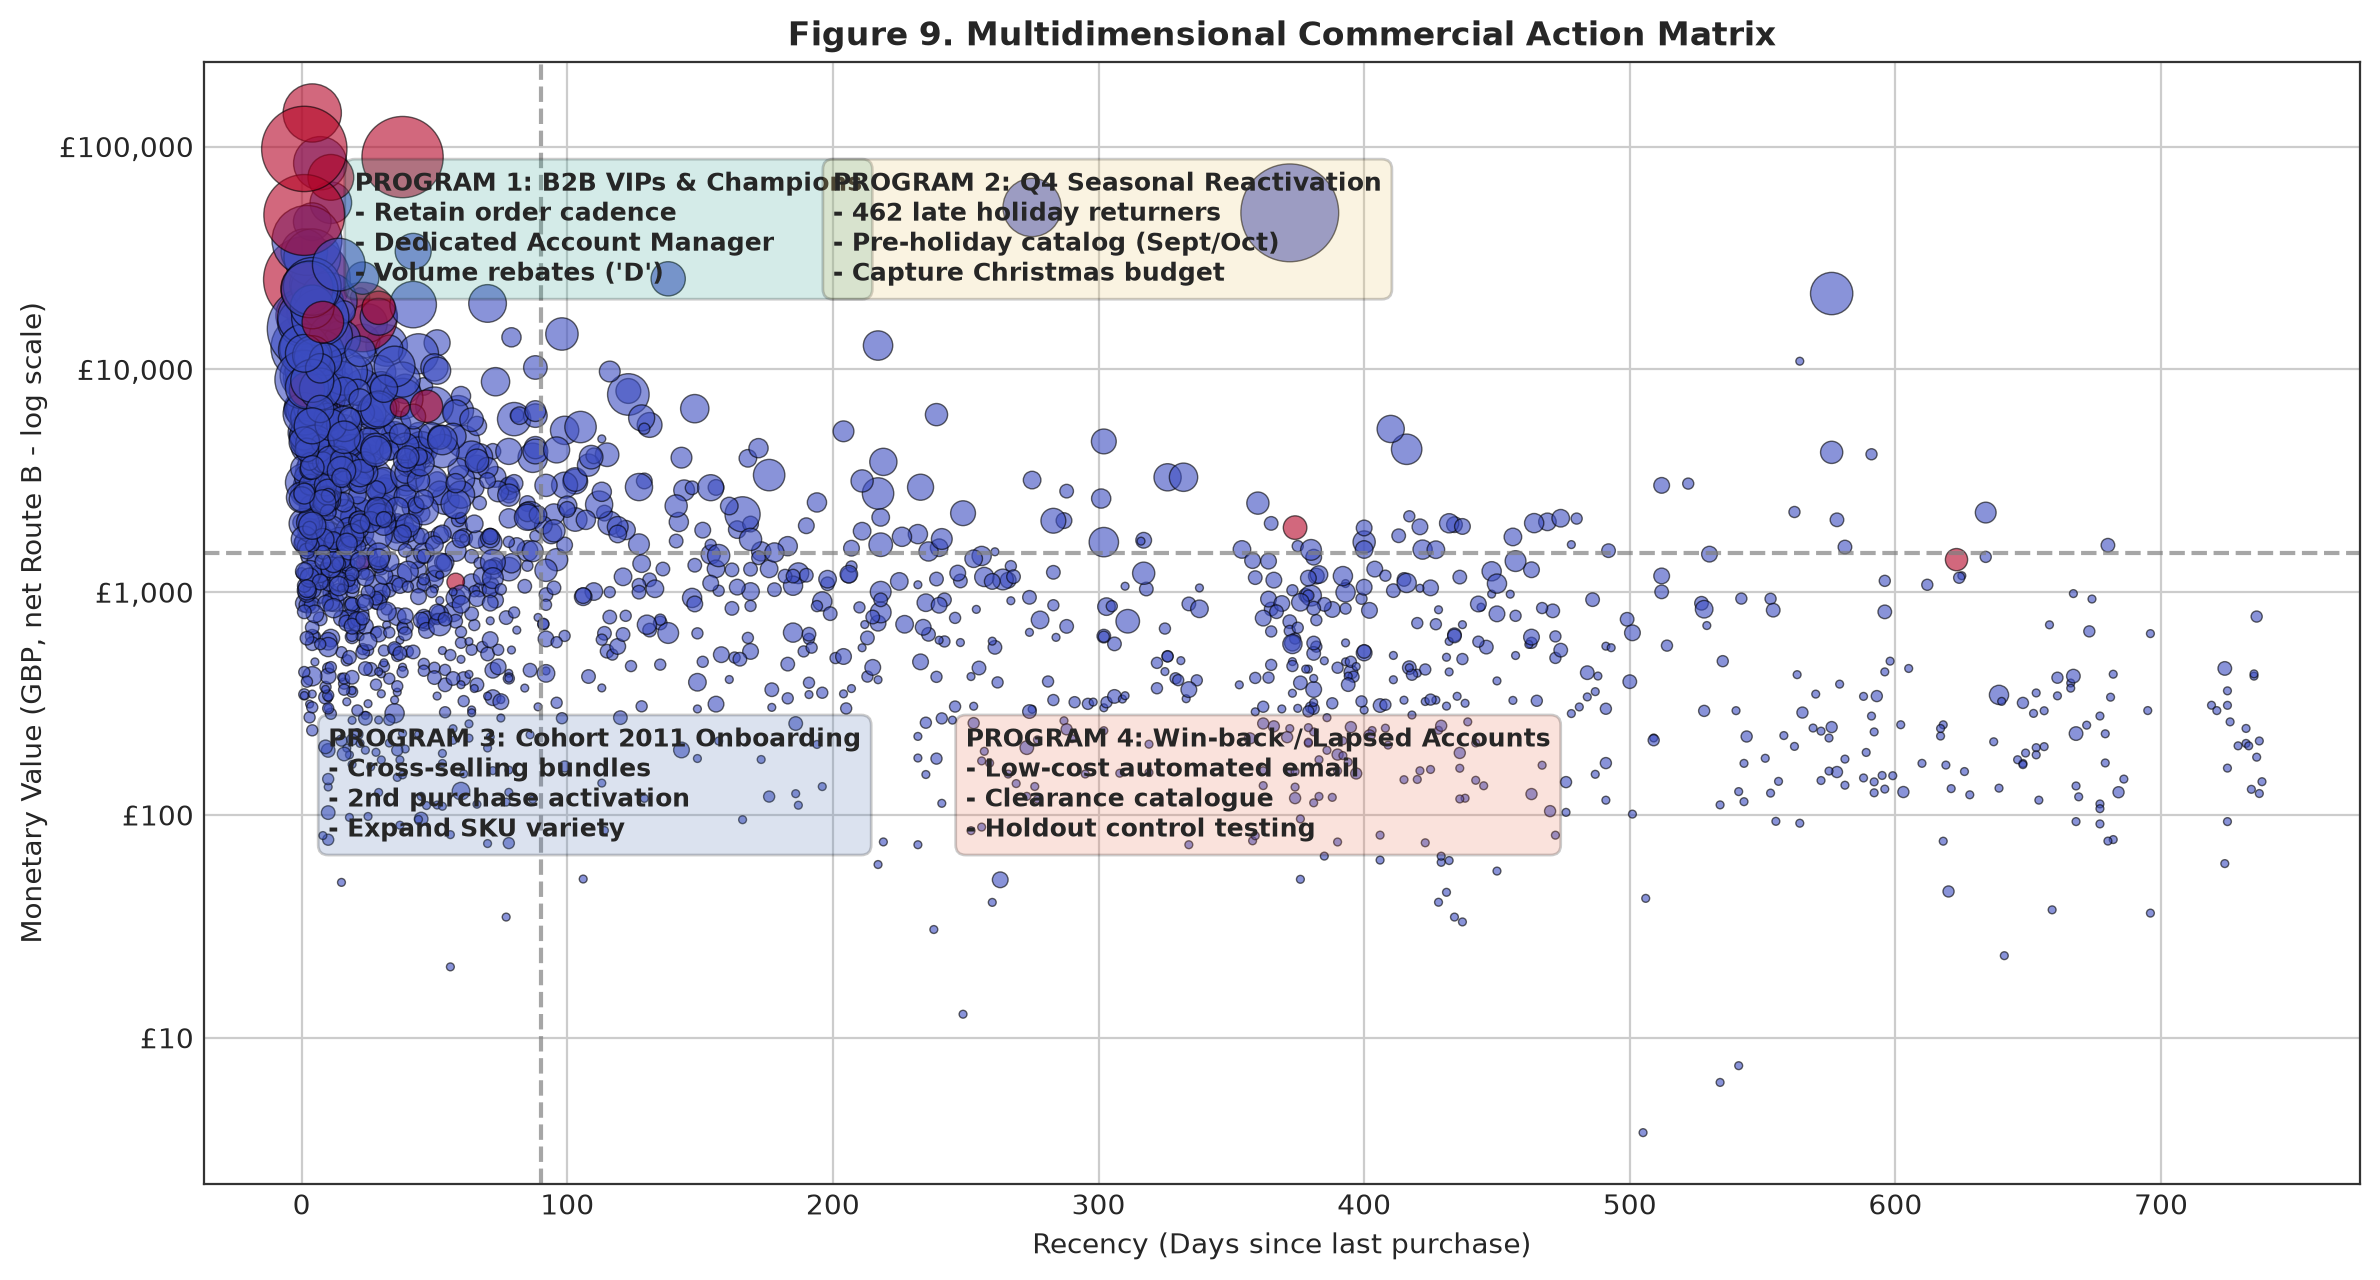

Figure 9 saved to figures/fig9_commercial_decision_matrix.png


In [26]:
fig, ax = plt.subplots(figsize=(12, 6.5), dpi=200)

sample_plot = pl.sample(1500, random_state=SEED) if len(pl) > 1500 else pl
disc_flags = rfm.set_index('CustomerID').loc[sample_plot.index, 'DISCOUNT_UserFlag'].fillna(0)

scatter = ax.scatter(sample_plot['Recency'], sample_plot['Monetary'],
                     c=disc_flags, cmap='coolwarm',
                     s=sample_plot['Frequency'] * 8, alpha=0.6, edgecolors='black', linewidth=0.5)

ax.set_yscale('log')
ax.set_title('Figure 9. Multidimensional Commercial Action Matrix', fontweight='bold', fontsize=12)
ax.set_xlabel('Recency (Days since last purchase)')
ax.set_ylabel('Monetary Value (GBP, net Route B - log scale)')
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('£{x:,.0f}'))

ax.axvline(90, color='grey', linestyle='--', alpha=0.7)
ax.axhline(1500, color='grey', linestyle='--', alpha=0.7)

ax.text(20, 25000, "PROGRAM 1: B2B VIPs & Champions\n- Retain order cadence\n- Dedicated Account Manager\n- Volume rebates ('D')",
        fontsize=9, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="#2a9d8f", alpha=0.2))

ax.text(200, 25000, "PROGRAM 2: Q4 Seasonal Reactivation\n- 462 late holiday returners\n- Pre-holiday catalog (Sept/Oct)\n- Capture Christmas budget",
        fontsize=9, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="#e9c46a", alpha=0.2))

ax.text(10, 80, "PROGRAM 3: Cohort 2011 Onboarding\n- Cross-selling bundles\n- 2nd purchase activation\n- Expand SKU variety",
        fontsize=9, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="#4c72b0", alpha=0.2))

ax.text(250, 80, "PROGRAM 4: Win-back / Lapsed Accounts\n- Low-cost automated email\n- Clearance catalogue\n- Holdout control testing",
        fontsize=9, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="#e76f51", alpha=0.2))

fig.tight_layout(); fig.savefig('figures/fig9_commercial_decision_matrix.png', bbox_inches='tight'); plt.show()
print('Figure 9 saved to figures/fig9_commercial_decision_matrix.png')

In [27]:
with open('outputs/resultados_actividad4.json', 'w', encoding='utf-8') as fh:
    json.dump(R, fh, ensure_ascii=False, indent=1, default=str)

keep[['CustomerID', 'Cluster', 'Segment', 'Recency', 'Frequency', 'Monetary']].to_csv('outputs/rfm_segments.csv', index=False)

print("\n" + "="*80)
print("FINAL ARTIFACTS VALIDATION (A-3-6):")
print("1. outputs/forecast_test_predictions.csv:", os.path.exists('outputs/forecast_test_predictions.csv'))
print("2. outputs/comparacion_modelos.csv:", os.path.exists('outputs/comparacion_modelos.csv'))
print("3. outputs/predicciones_clasificacion.csv:", os.path.exists('outputs/predicciones_clasificacion.csv'))
print("4. outputs/clientes_rfm_segmentados.csv:", os.path.exists('outputs/clientes_rfm_segmentados.csv'))
print("5. outputs/rfm_segments.csv:", os.path.exists('outputs/rfm_segments.csv'))
print("6. outputs/customer_priority_list.csv:", os.path.exists('outputs/customer_priority_list.csv'))
print("7. outputs/resultados_actividad4.json:", os.path.exists('outputs/resultados_actividad4.json'))
print("="*80)


FINAL ARTIFACTS VALIDATION (A-3-6):
1. outputs/forecast_test_predictions.csv: True
2. outputs/comparacion_modelos.csv: True
3. outputs/predicciones_clasificacion.csv: True
4. outputs/clientes_rfm_segmentados.csv: True
5. outputs/rfm_segments.csv: True
6. outputs/customer_priority_list.csv: True
7. outputs/resultados_actividad4.json: True
